In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

# Automatically locate your active Miniconda environment's plugin directory
conda_prefix = os.environ.get("CONDA_PREFIX")
if conda_prefix:
    # On Windows, Conda puts plugin DLLs in Library\bin\gdalplugins
    plugin_path = os.path.join(conda_prefix, "Library", "lib", "gdalplugins")
    os.environ["GDAL_DRIVER_PATH"] = plugin_path
    # Append the main bin directory to the system PATH so dependencies load
    os.environ["PATH"] = os.path.join(conda_prefix, "Library", "lib") + os.pathsep + os.environ["PATH"]

from interpolation_uncertainty import (
    read_file, show_depth,
    build_coverage_mask,
    compute_local_orientation,
    undo_rotation,
    compute_uncertainty,
    detect_trackline_positions, assign_depths_to_lines,
    build_uncertainty_raster,
)

# scikit-image functions used directly in notebook cells
from skimage.morphology import opening, thin, disk

import numpy as np
import matplotlib.pyplot as plt

## Trackline Detection via combined Radon Transform and Local Angle Detection

This notebook detects and extracts individual **survey tracklines** from a bathymetric raster by exploiting the linear spatial structure left by vessel survey passes.

**Overall pipeline:**

1. Load the BAG raster 
2. Build a binary coverage mask.
3. Apply morphological filtering to suppress blob-like dense coverage patches, leaving only thin linear trackline structures.
4. Skeletonise the filtered image to single-pixel-width lines.
5. Use the **Radon transform** to identify the dominant line orientations (angle peaks).
6. Compute local angle orientation of points using PCA
6. Iteratively extract line families: for each dominant angle, rotate the original bathymetry to align it to the vertical axis and sample the points that intersect with the vertical lines defined by the angle peaks 
7. For each extracted family, assign real depth values based on original data
8. With each extracted family now consisting of parallel lines, we can process pairs of lines iteratively

For each pair of lines:

9. Interpolated bathymetry values of there are gaps within the lines
10. Compute the uncertainty for each line in the pair using the spectral energy using distance between the pair of lines as "linespacing"
11. Divide each line into subsegments with lengths equal to linespacing and apply spectral energy computation on each subsegment resulting to 2D array of spectral energies
12. Place the computed 2D arrays to the space between the line pairs

After processing all line pairs:

13. Rotate the resulting raster back to its original orientation (negative of dominant angle)
14. Plot the resulting raster

1. Load the BAG raster

Load the BAG (Bathymetric Attributed Grid) raster file. The result is a dict containing the raw 2D depth array and metadata (geotransform, resolution, no-data value). No-data values are **not** masked on load — they are handled explicitly in subsequent steps.

File '../data/raster/H12315_VB_4m_MLLW_2of2.bag' read successfully.
Data shape: 3860 rows x 6064 columns
No-data value: 1000000.0
Resolution: 4.0 m/pixel
Geotransform values--> 
Origin x-coordinate: 405230.0
Pixel width: 4.0
Row rotation: 0.0
Origin y-coordinate: 4088854.0
Column rotation: 0.0
Pixel height: -4.0



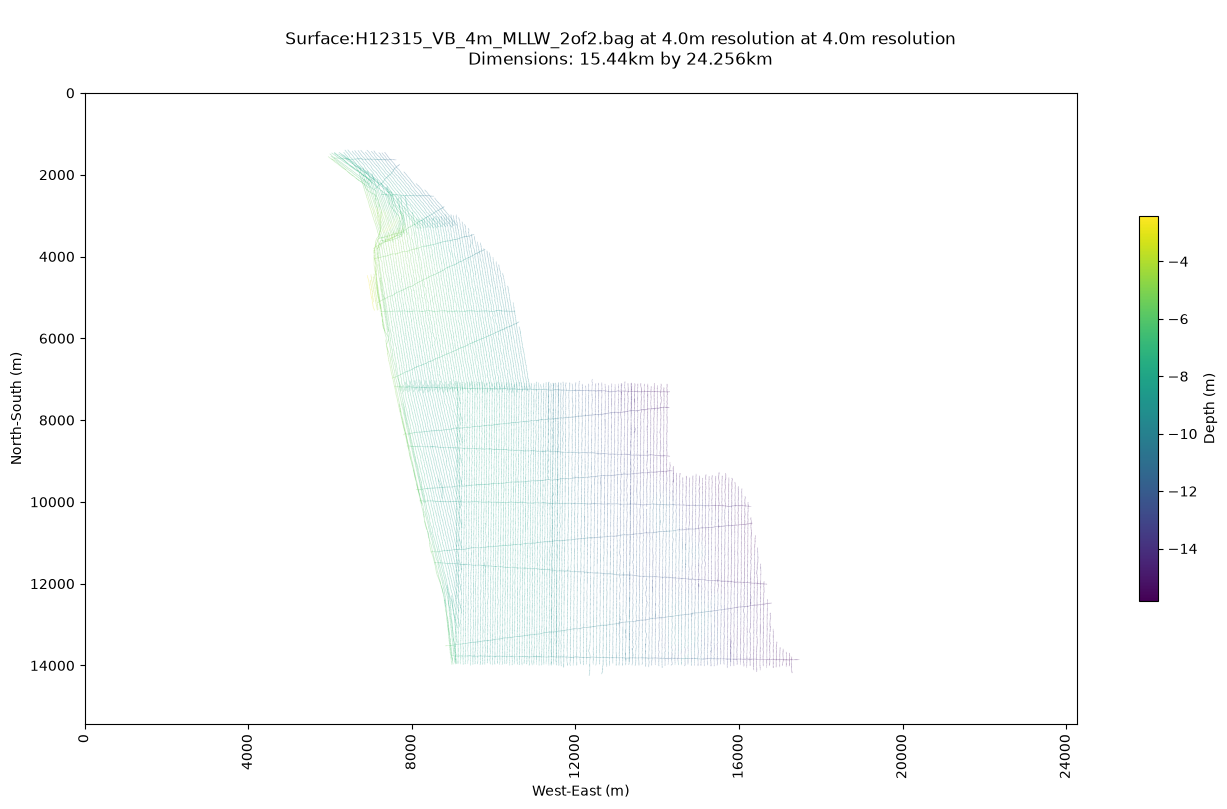

In [3]:
fn = r"../data/raster/H12315_VB_4m_MLLW_2of2.bag"
bathy_data = read_file(fn, verbose=True)

# Visualize the loaded bathymetric data
show_depth(bathy_data, cmap='viridis')

2. Build a binary coverage mask

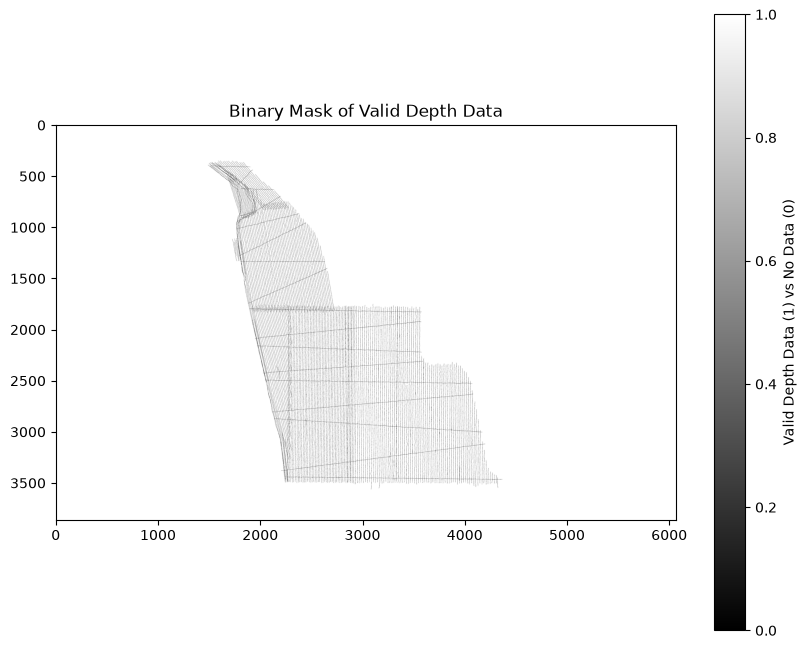

In [4]:
bathy_binary = build_coverage_mask(bathy_data)

plt.figure(figsize=(10, 8))
plt.imshow(1 - bathy_binary, cmap='gray')
plt.colorbar(label='Valid Depth Data (1) vs No Data (0)')
plt.title("Binary Mask of Valid Depth Data")
plt.show()

3. Apply morphological filtering to suppress blob-like patches
4. Skeletonise the filtered image to single-pixel-width lines

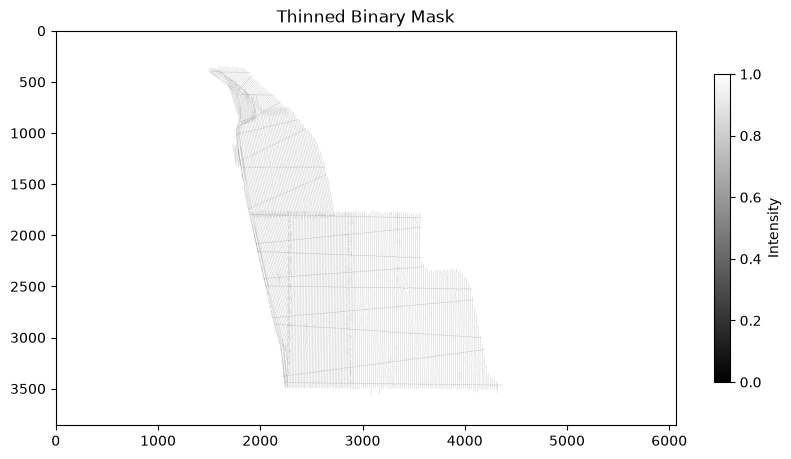

In [5]:
# Apply morphological thinning to the binary mask
# Remove blob-like structures while preserving the skeleton of valid data
bathy_blobs = opening(bathy_binary, disk(5))  # Remove small blobs
bathy_lines = bathy_binary & ~bathy_blobs  # Keep only the line-like structures
bathy_thin = thin(bathy_lines) > 0
plt.figure(figsize=(10, 8))
plt.imshow(1 - bathy_thin, cmap='gray')
plt.title("Thinned Binary Mask")
plt.colorbar(label='Intensity', shrink=0.5)
plt.show()


In [6]:
bathy_thin.shape

(3860, 6064)

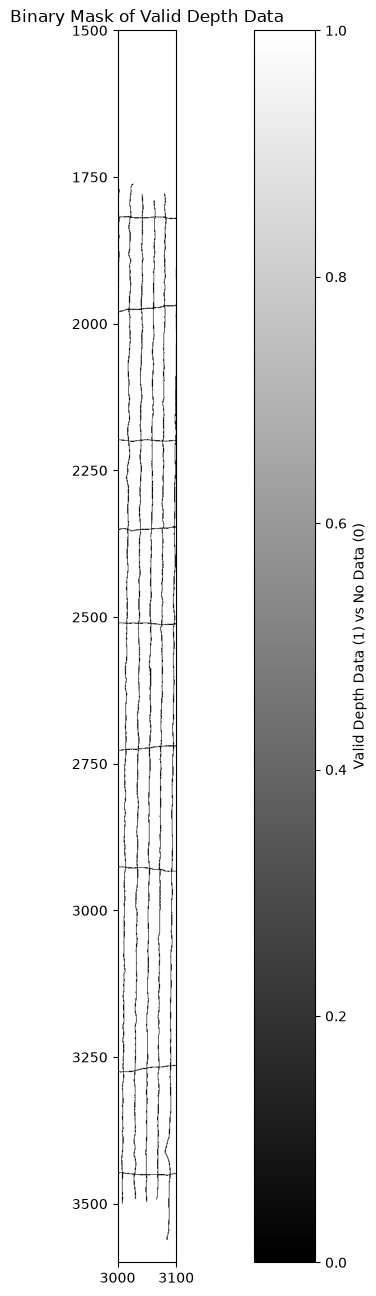

In [10]:
plt.figure(figsize=(20, 16))
plt.imshow(1 - bathy_binary, cmap='gray')
plt.colorbar(label='Valid Depth Data (1) vs No Data (0)')
plt.title("Binary Mask of Valid Depth Data")
plt.xlim([3000, 3100])
plt.ylim([3600, 1500])
plt.show()
# 20pixels wide, 2400 pixels tall
# overlap is at midpoint (10 pixels)
# minimum angle resolution = arcsin(10/1200) = 0.477 degree
# minimum angle resolution = arcsin(10/2400) = 0.239 degree

5. Use the **Radon transform** to identify the dominant line orientations (angles).

In [7]:
angle_info = None

Computing Radon transform...


C:\Users\personal\miniconda3\envs\interpolation_uncertainty\Lib\site-packages\skimage\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


Radon Computation Done.
Detected peaks (radon):[ 13  39  89 114]
Detected peaks (xy):[103 129 179  24]
Plotting peaks...
Plotting angle family 103...
number of lines: 32 
Plotting angle family 129...
number of lines: 3 
Plotting angle family 179...
number of lines: 3 
Plotting angle family 24...
number of lines: 0 
Labeling points...
Labeling points... Done.


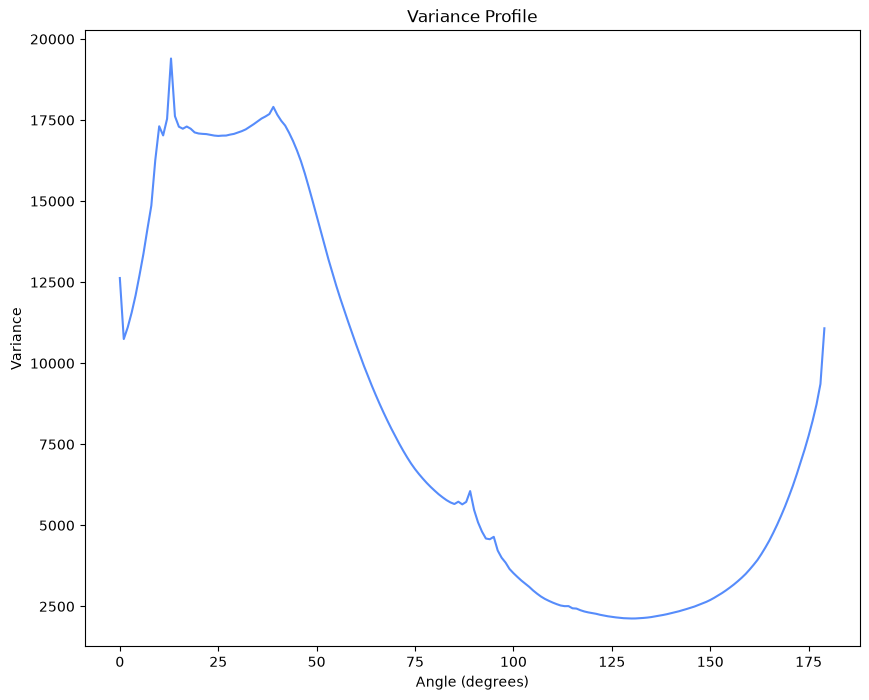

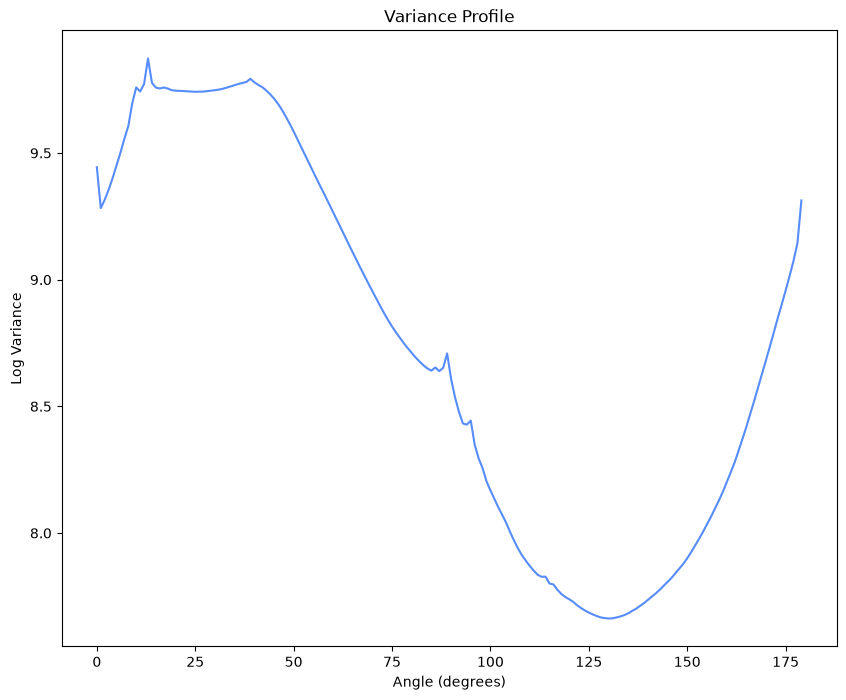

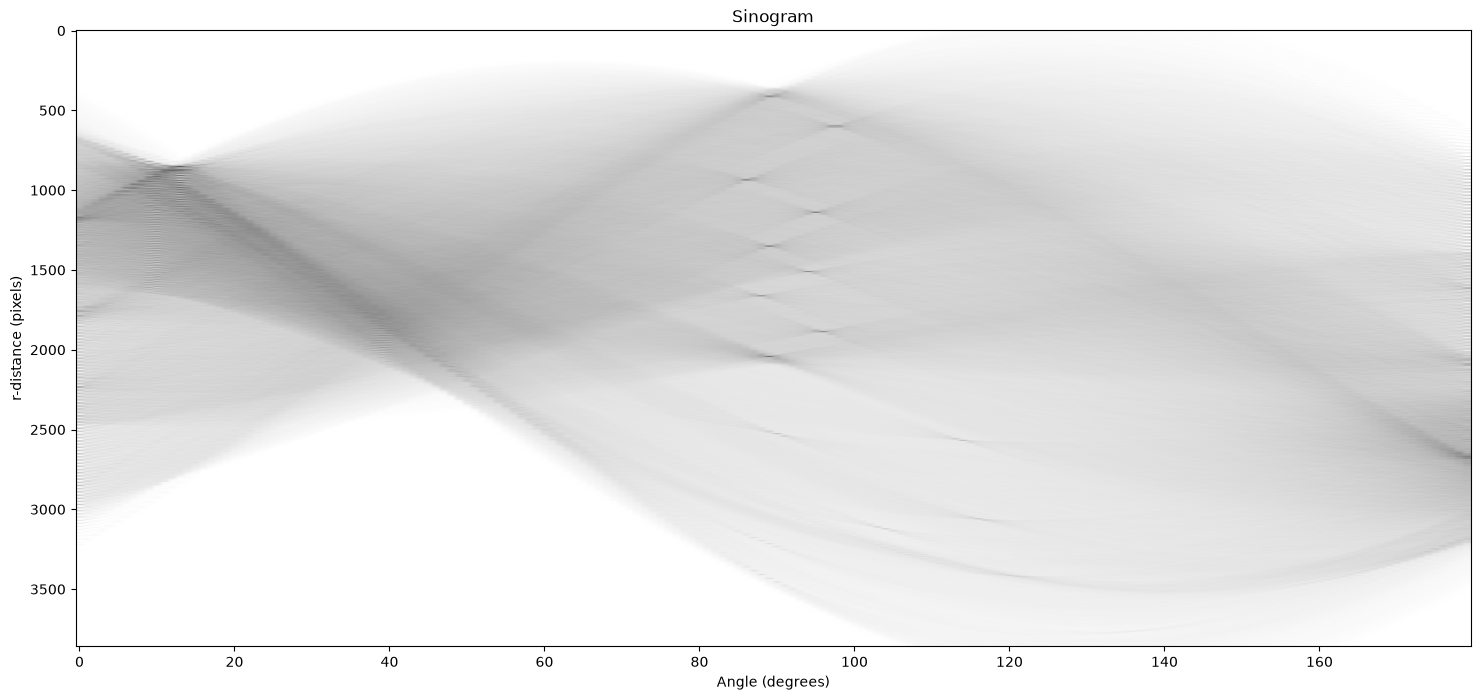

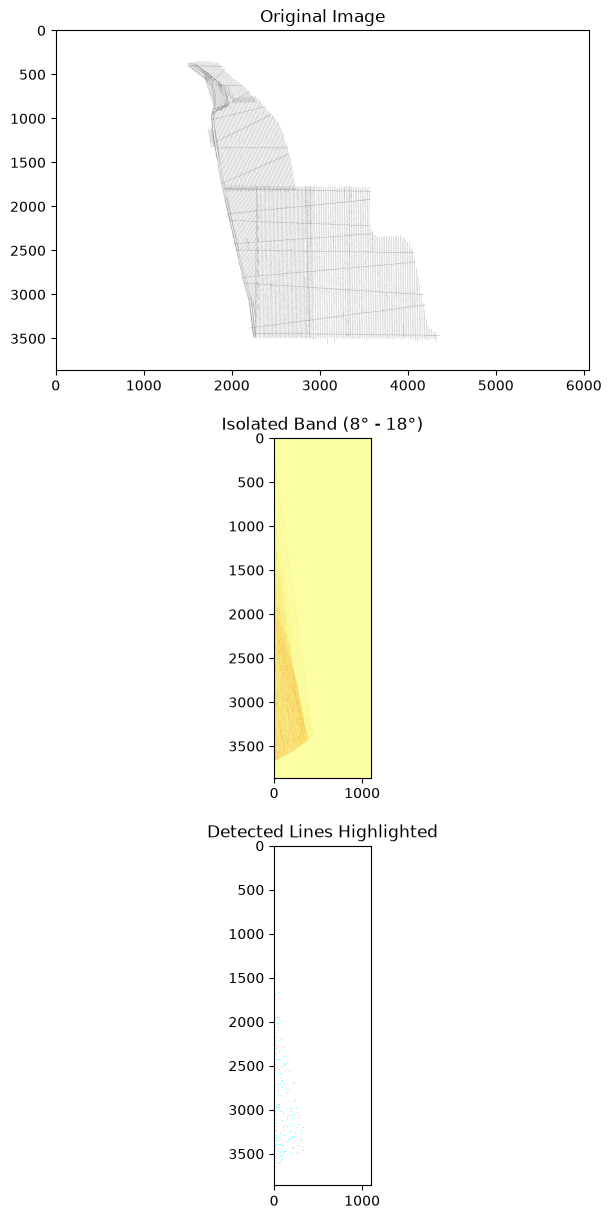

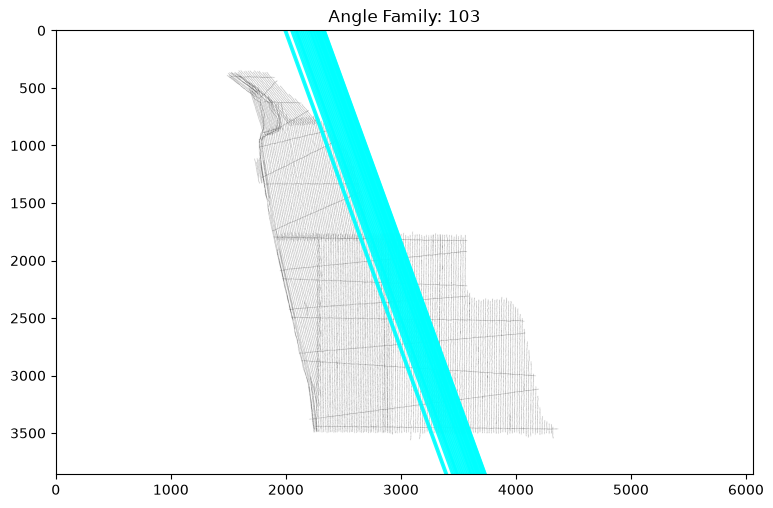

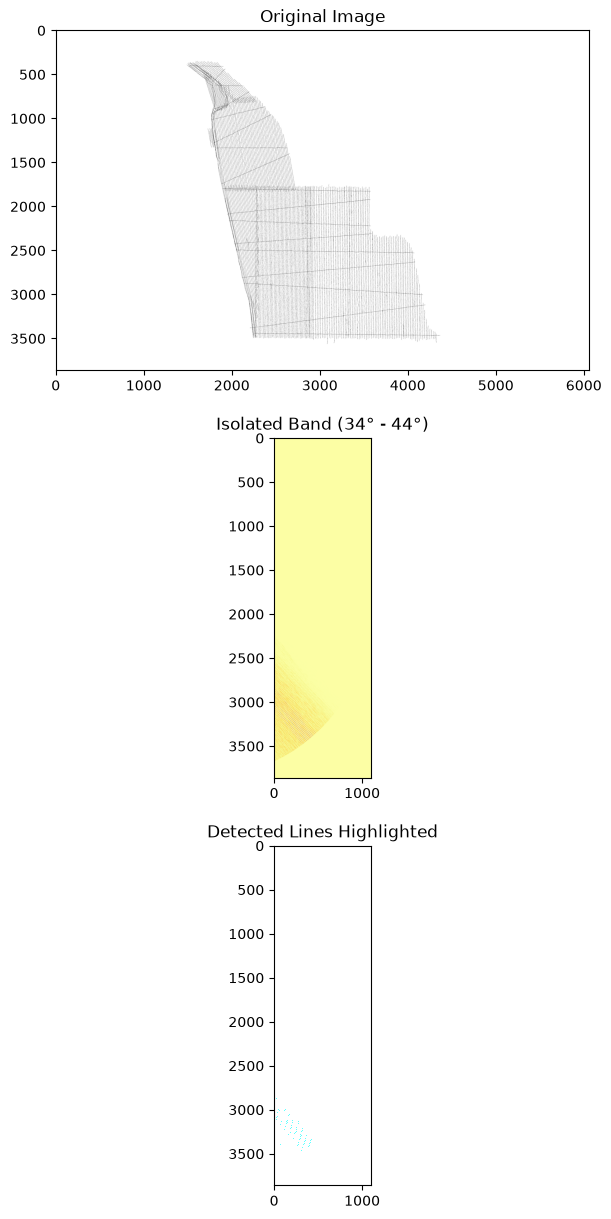

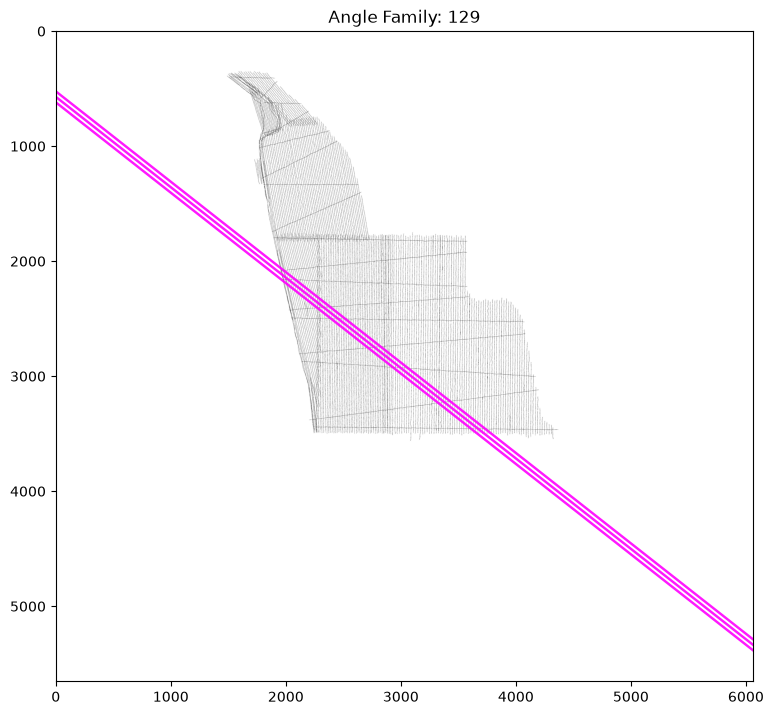

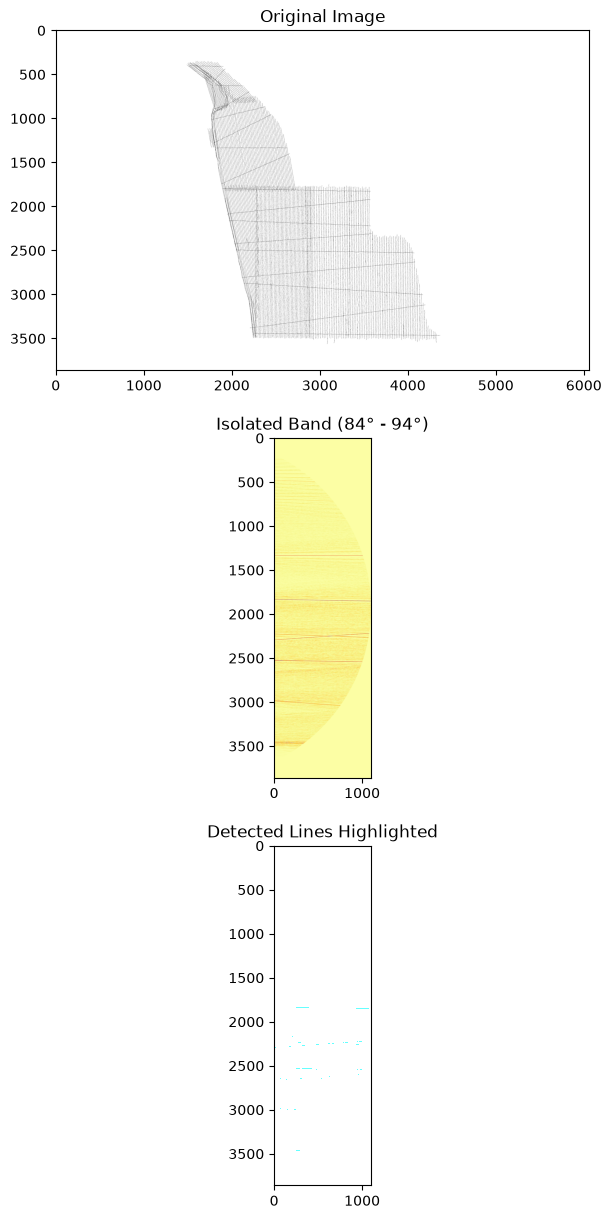

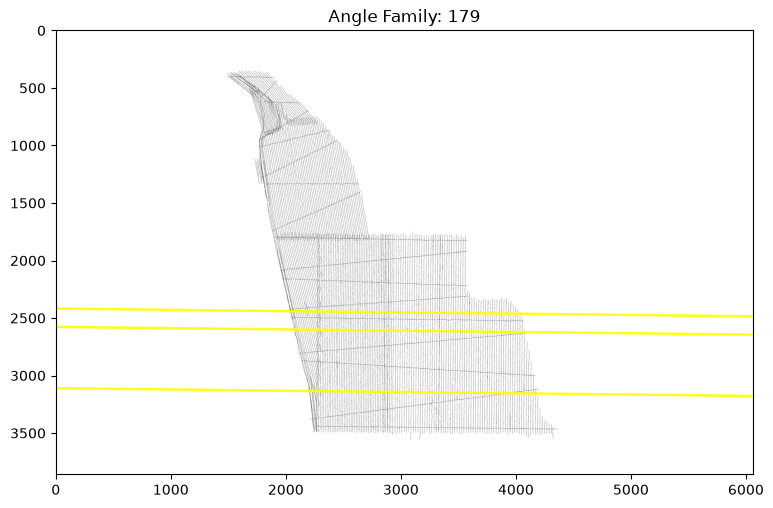

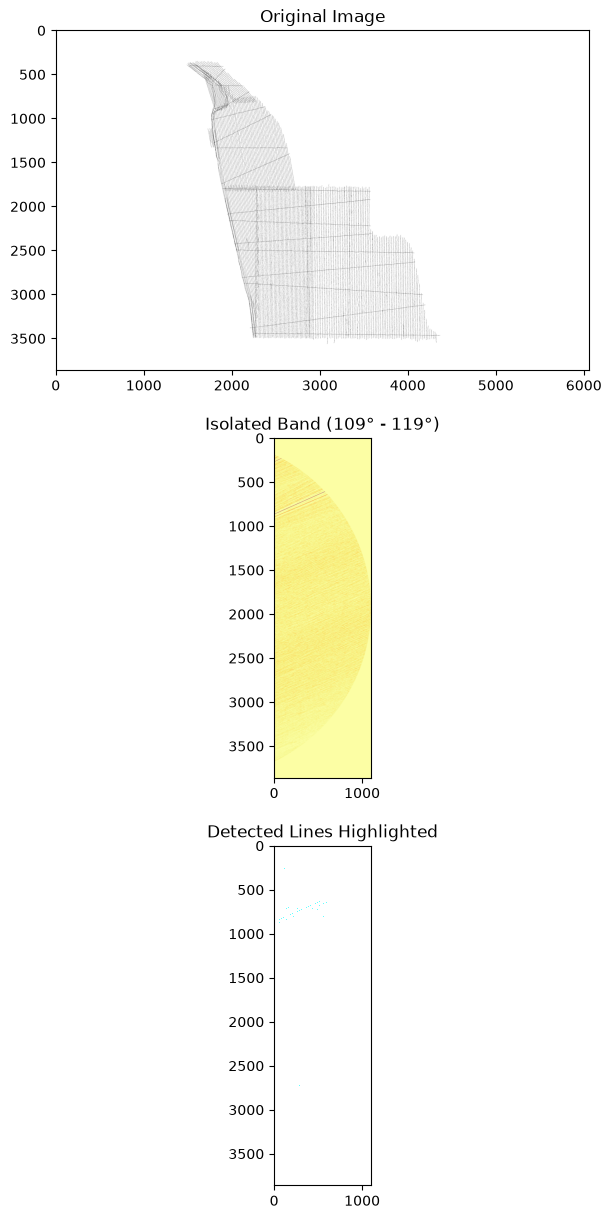

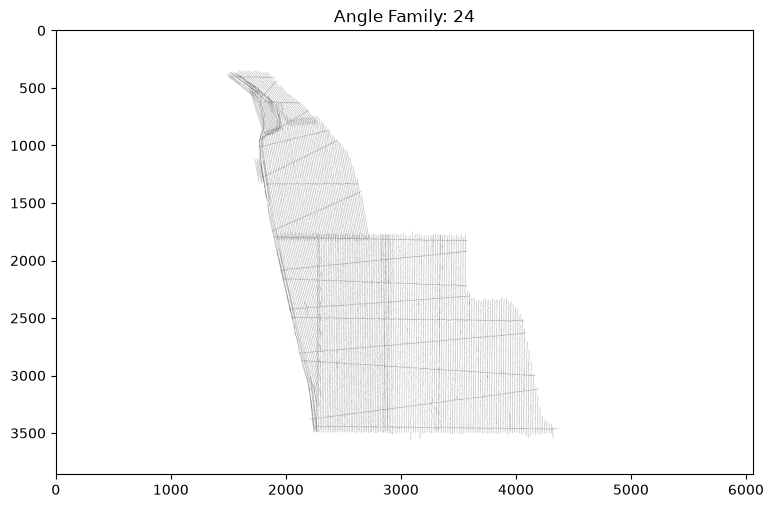

In [5]:
# Run the Radon transform over the full skeleton to identify the single most
# prominent orientation. The variance profile peaks at angles where projections
# are concentrated — characteristic of linear features aligned with that angle.
angle_info = None
point_orientation, angle_info = compute_local_orientation(bathy_binary,
                                  method='radon',
                                  plot_orientation=False,
                                  circle=True,
                                  angular_tolerance=5,
                                  pixel_tolerance=5,
                                  min_intensity=5,
                                  do_offset=True,
                                  precomputed_theta=angle_info)


In [91]:
line_families = np.unique(point_orientation)
print(f"Detected {len(line_families)} line families")
print(f"Line families: {line_families}")

Detected 6 line families
Line families: [  5.  90. 103. 129. 176.  nan]


ValueError: cannot convert float NaN to integer

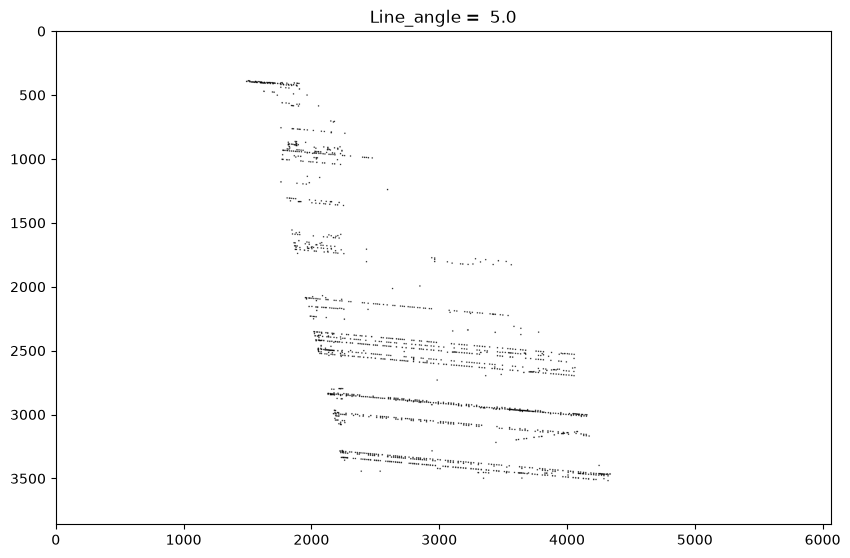

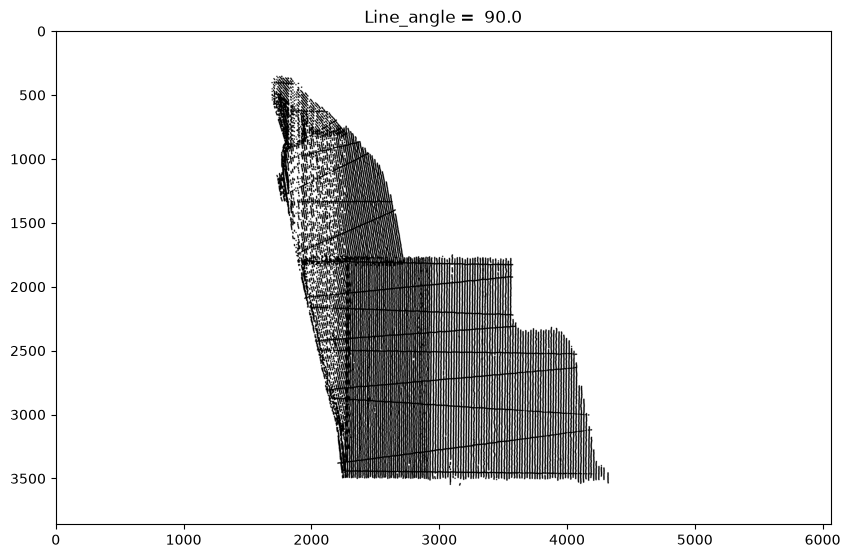

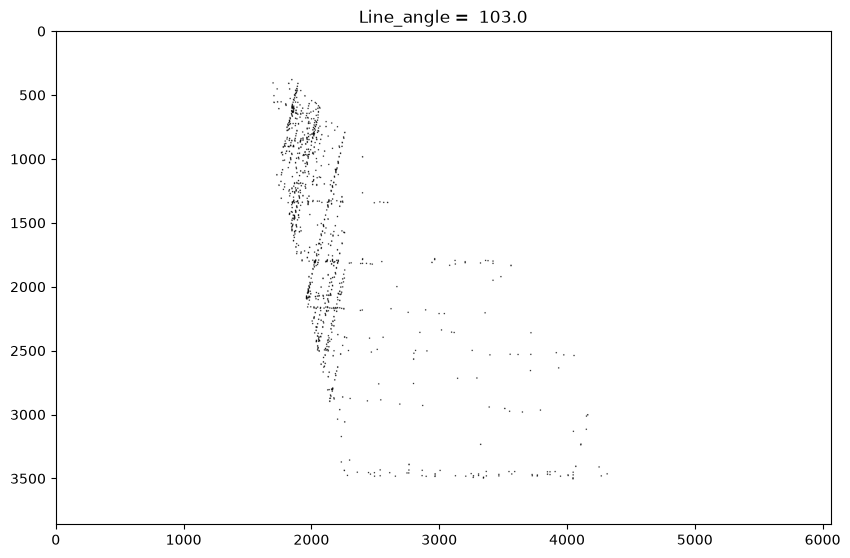

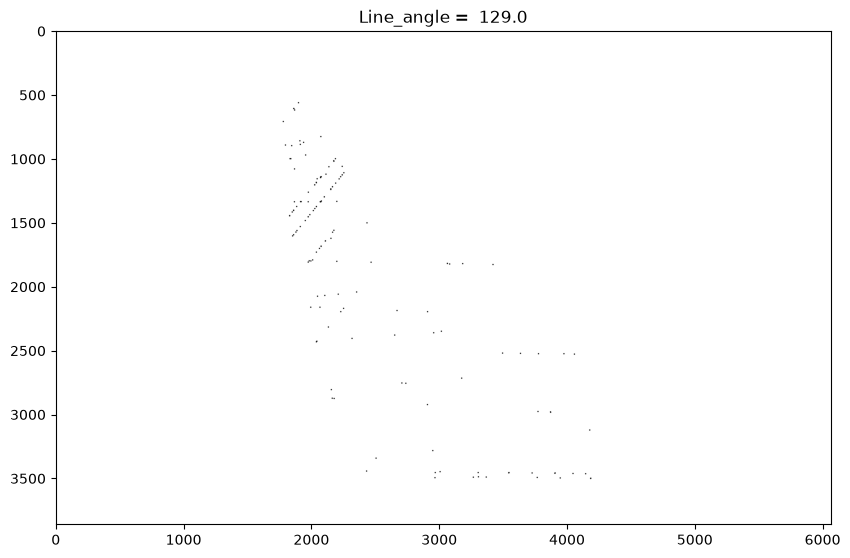

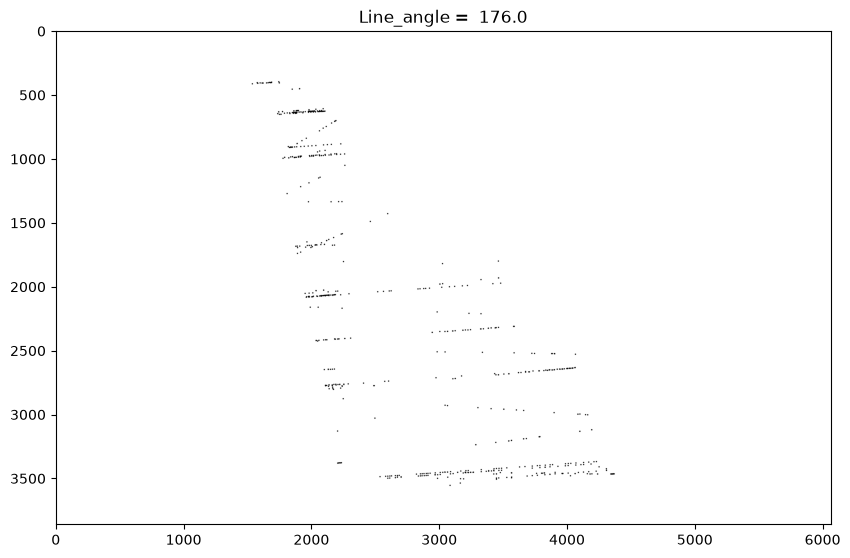

In [92]:
from skimage.morphology import dilation, disk
for line_family in line_families:
    if int(line_family) == np.nan:
        continue
    current_family = (point_orientation == line_family)
    current_family = dilation(current_family, disk(radius=5))
    plt.figure(figsize=(10, 8))
    plt.imshow(1 - current_family, cmap='gray')
    plt.title(f"Line_angle =  {line_family}")

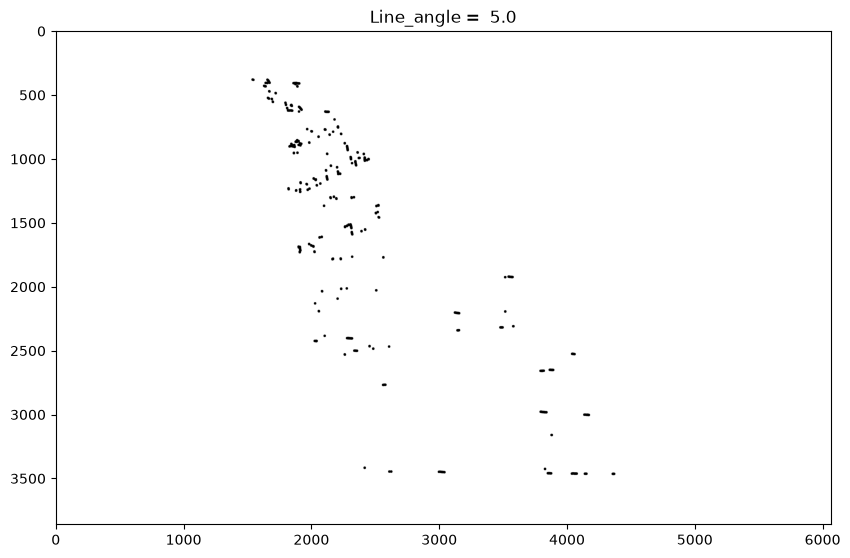

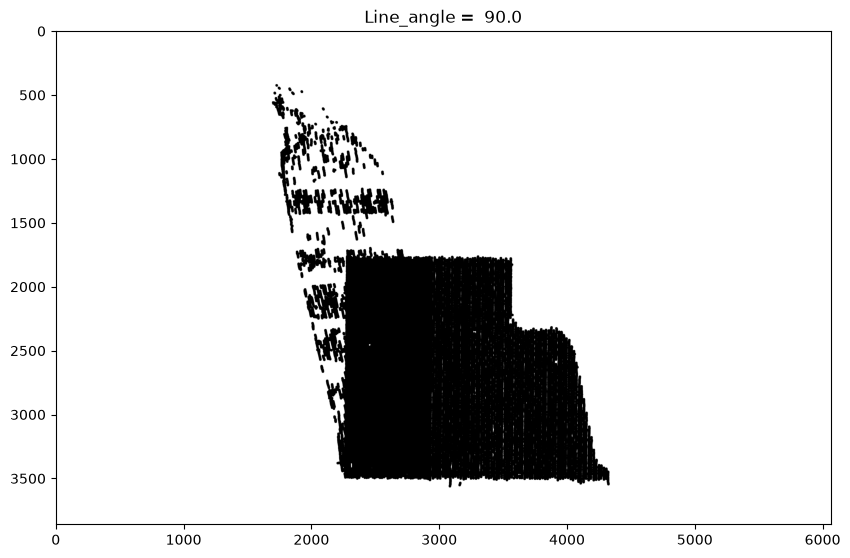

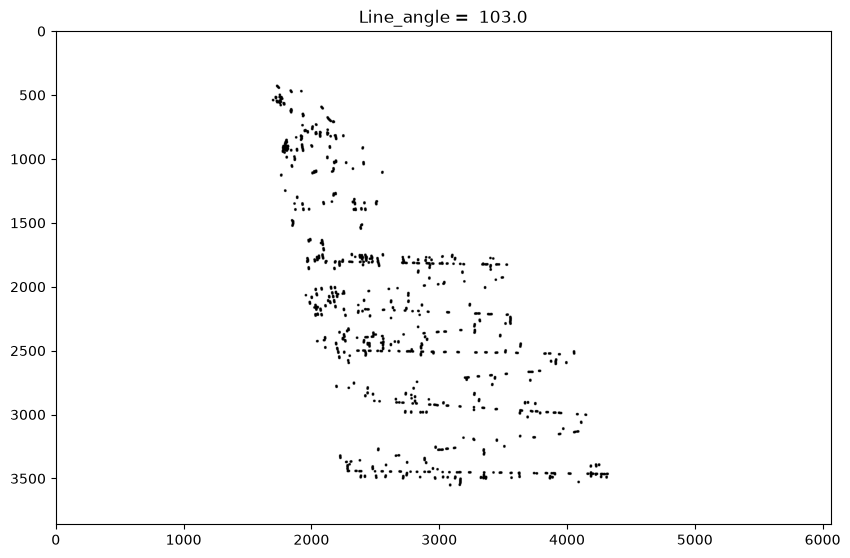

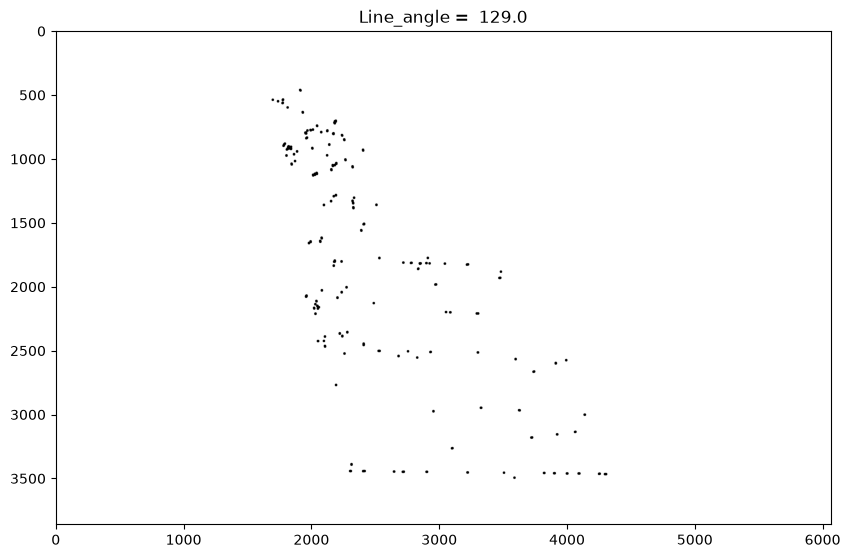

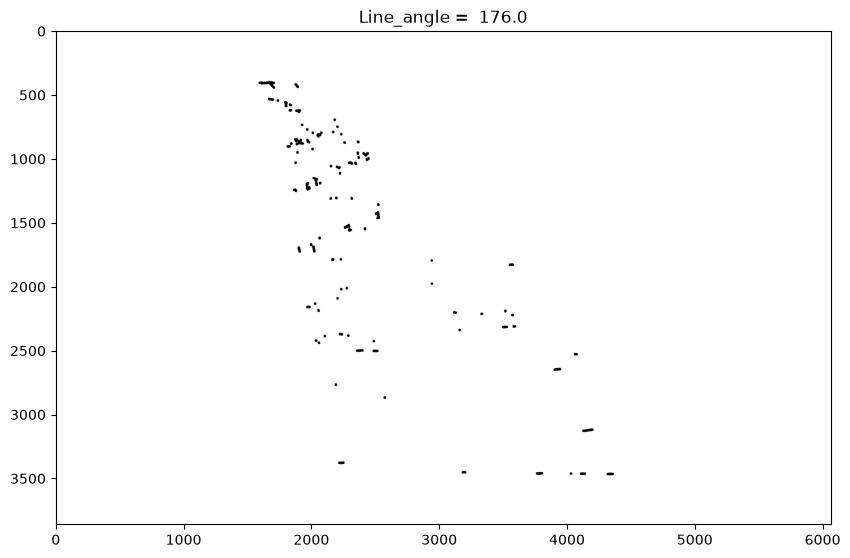

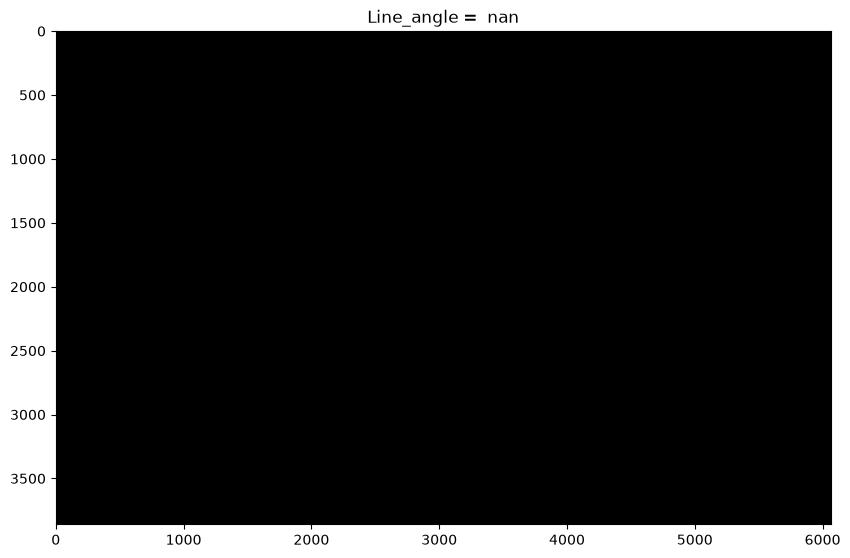

In [83]:

from skimage.morphology import dilation, disk
for line_family in line_families:
    if line_family == 'nan':
        continue
    current_family = (point_orientation == line_family)
    current_family = dilation(current_family, disk(radius=10))
    plt.figure(figsize=(10, 8))
    plt.imshow(1 - current_family, cmap='gray')
    plt.title(f"Line_angle =  {line_family}")

In [8]:
from interpolation_uncertainty.preprocessing.orientation import label_points_by_angle

In [14]:
X_linear = np.argwhere(bathy_thin)
peak_centers, labels = label_points_by_angle(X_linear[:, 1],
                                             X_linear[:, 0],
                                             output[0])

In [15]:
peak_centers

array([ -44.07348744,  -28.09015071,  -16.16658061,  -14.1523353 ,
        -12.05727358,   -8.09775207,   -5.11097133,   11.87983892,
         17.86635939,   22.90996425,   25.89452144,   30.94385352,
         32.86398674,   39.86884397,   45.85259467,   51.73779025,
         55.97059414,   57.81475869,   63.85080694,   65.85558559,
         73.82157382,   75.8189767 ,   77.89163084,   82.98994063,
         84.8466962 ,   91.86379975,   96.719035  ,  102.88524471,
        104.89413617,  107.88834077,  113.91870397,  116.87698758,
        119.77099282,  127.87511008,  131.89315143,  138.89217568,
        142.95628034,  147.93292267,  150.80846149,  153.82125128,
        161.81694217,  166.78716134,  169.91847903,  171.81398819,
        180.93174582,  182.8294132 ,  186.88960334,  189.95736696,
        195.79015063,  204.81252299,  207.83728688,  210.90083687,
        213.89001549,  215.89568942,  221.91441869,  236.85440521,
        242.90149473,  247.90709431,  252.83930446,  256.87196

In [16]:
labels

array([-1, -1, -1, ..., -1, -1, -1], shape=(284406,))

In [9]:
output_labels

[array([739, 739, 740, ..., 343, 343, 343], shape=(284406,))]

In [17]:
unique_labels = np.unique(output_labels)
X_linear = np.copy(bathy_thin)

In [18]:
print(unique_labels)

[ -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16
  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34
  35  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52
  53  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70
  71  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88
  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106
 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124
 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142
 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160
 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178
 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196
 197 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214
 215 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232
 233 234 235 236 237 238 239 240 241 242 243 244 24

IndexError: list index out of range

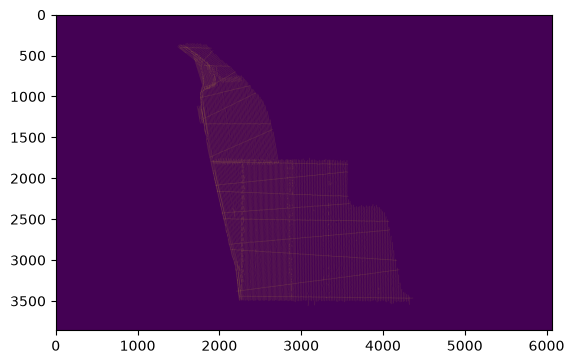

In [19]:

for i,unique_label in enumerate(unique_labels[1:]):
    X_linear[unique_labels, 0][:-1] = output_peaks[i]
    X_linear[unique_labels, 1][:-1] = output_peaks[i]
    plt.imshow(X_linear)

In [7]:
print(f"Dominant Orientations: {dominant_orientations['peaks']}")

Dominant Orientations: [103 129 179 100   5 176 107]


6. Compute local angle orientation of points using PCA

100%|██████████| 284406/284406 [03:23<00:00, 1398.51it/s]


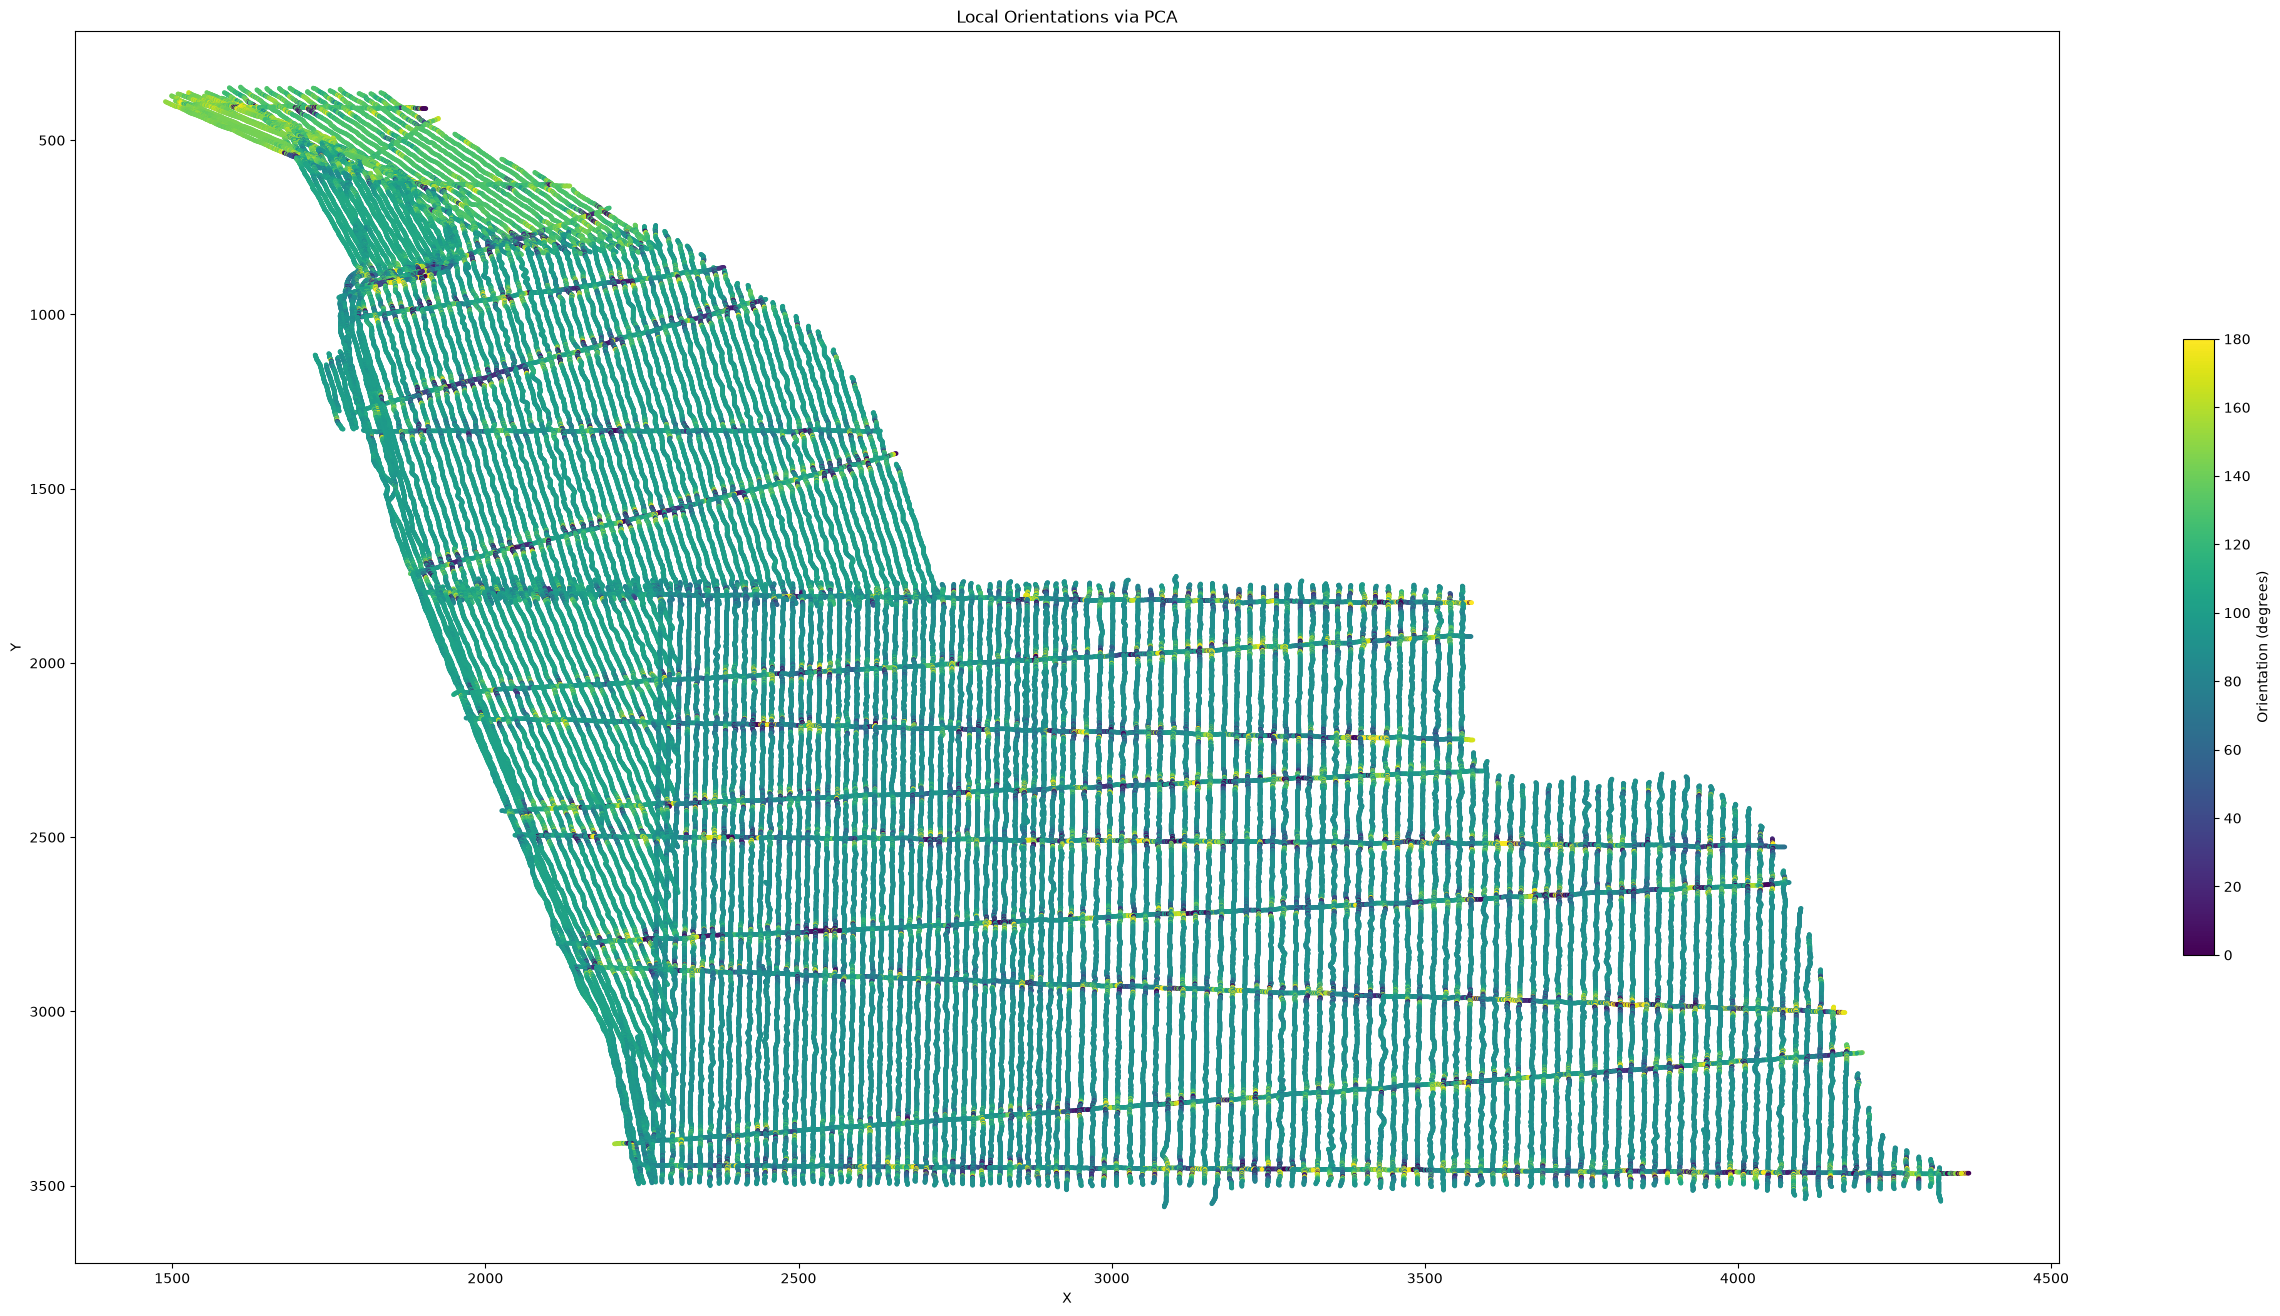

In [8]:
local_orientations = compute_local_orientation(
    binary_image=bathy_thin,
    line_length=50,
    num_neighbors=20,
    plot_orientation=True,
    cmap = 'viridis',
    figsize=(32, 16)
)

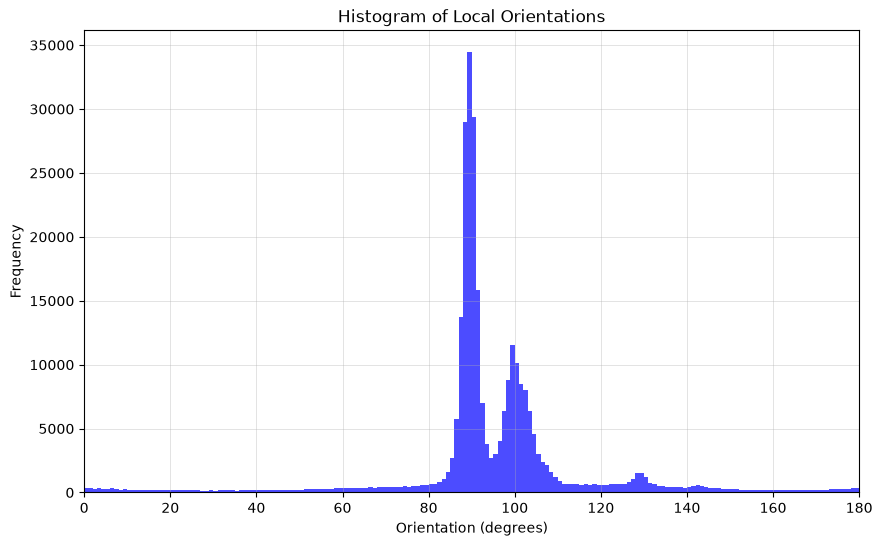

In [9]:
# Compute histogram of local orientations
plt.figure(figsize=(10, 6))
min_angle = np.nanmin(local_orientations)
max_angle = np.nanmax(local_orientations)
plt.hist(local_orientations[~np.isnan(local_orientations)].flatten(), bins=180, range=(min_angle, max_angle), color='blue', alpha=0.7)
plt.title("Histogram of Local Orientations")
plt.xlabel("Orientation (degrees)")
plt.ylabel("Frequency")
plt.xlim(min_angle, max_angle)
plt.grid(True)
plt.show()

6. Iteratively extract line families: for each dominant angle, rotate the original bathymetry to align it to the vertical axis and sample the points that intersect with the vertical lines defined by the angle peaks

In [10]:
TARGET_ANGLES = dominant_orientations['peaks']

# Override detected TARGET_ANGLES as necessary
TARGET_ANGLES = [90, 103, 129]

Using min_line_length = 121 pixels (2.0% of max dimension)
Extracting lines around 90° ± 5°
  Angle range: 85.0° to 95.0°


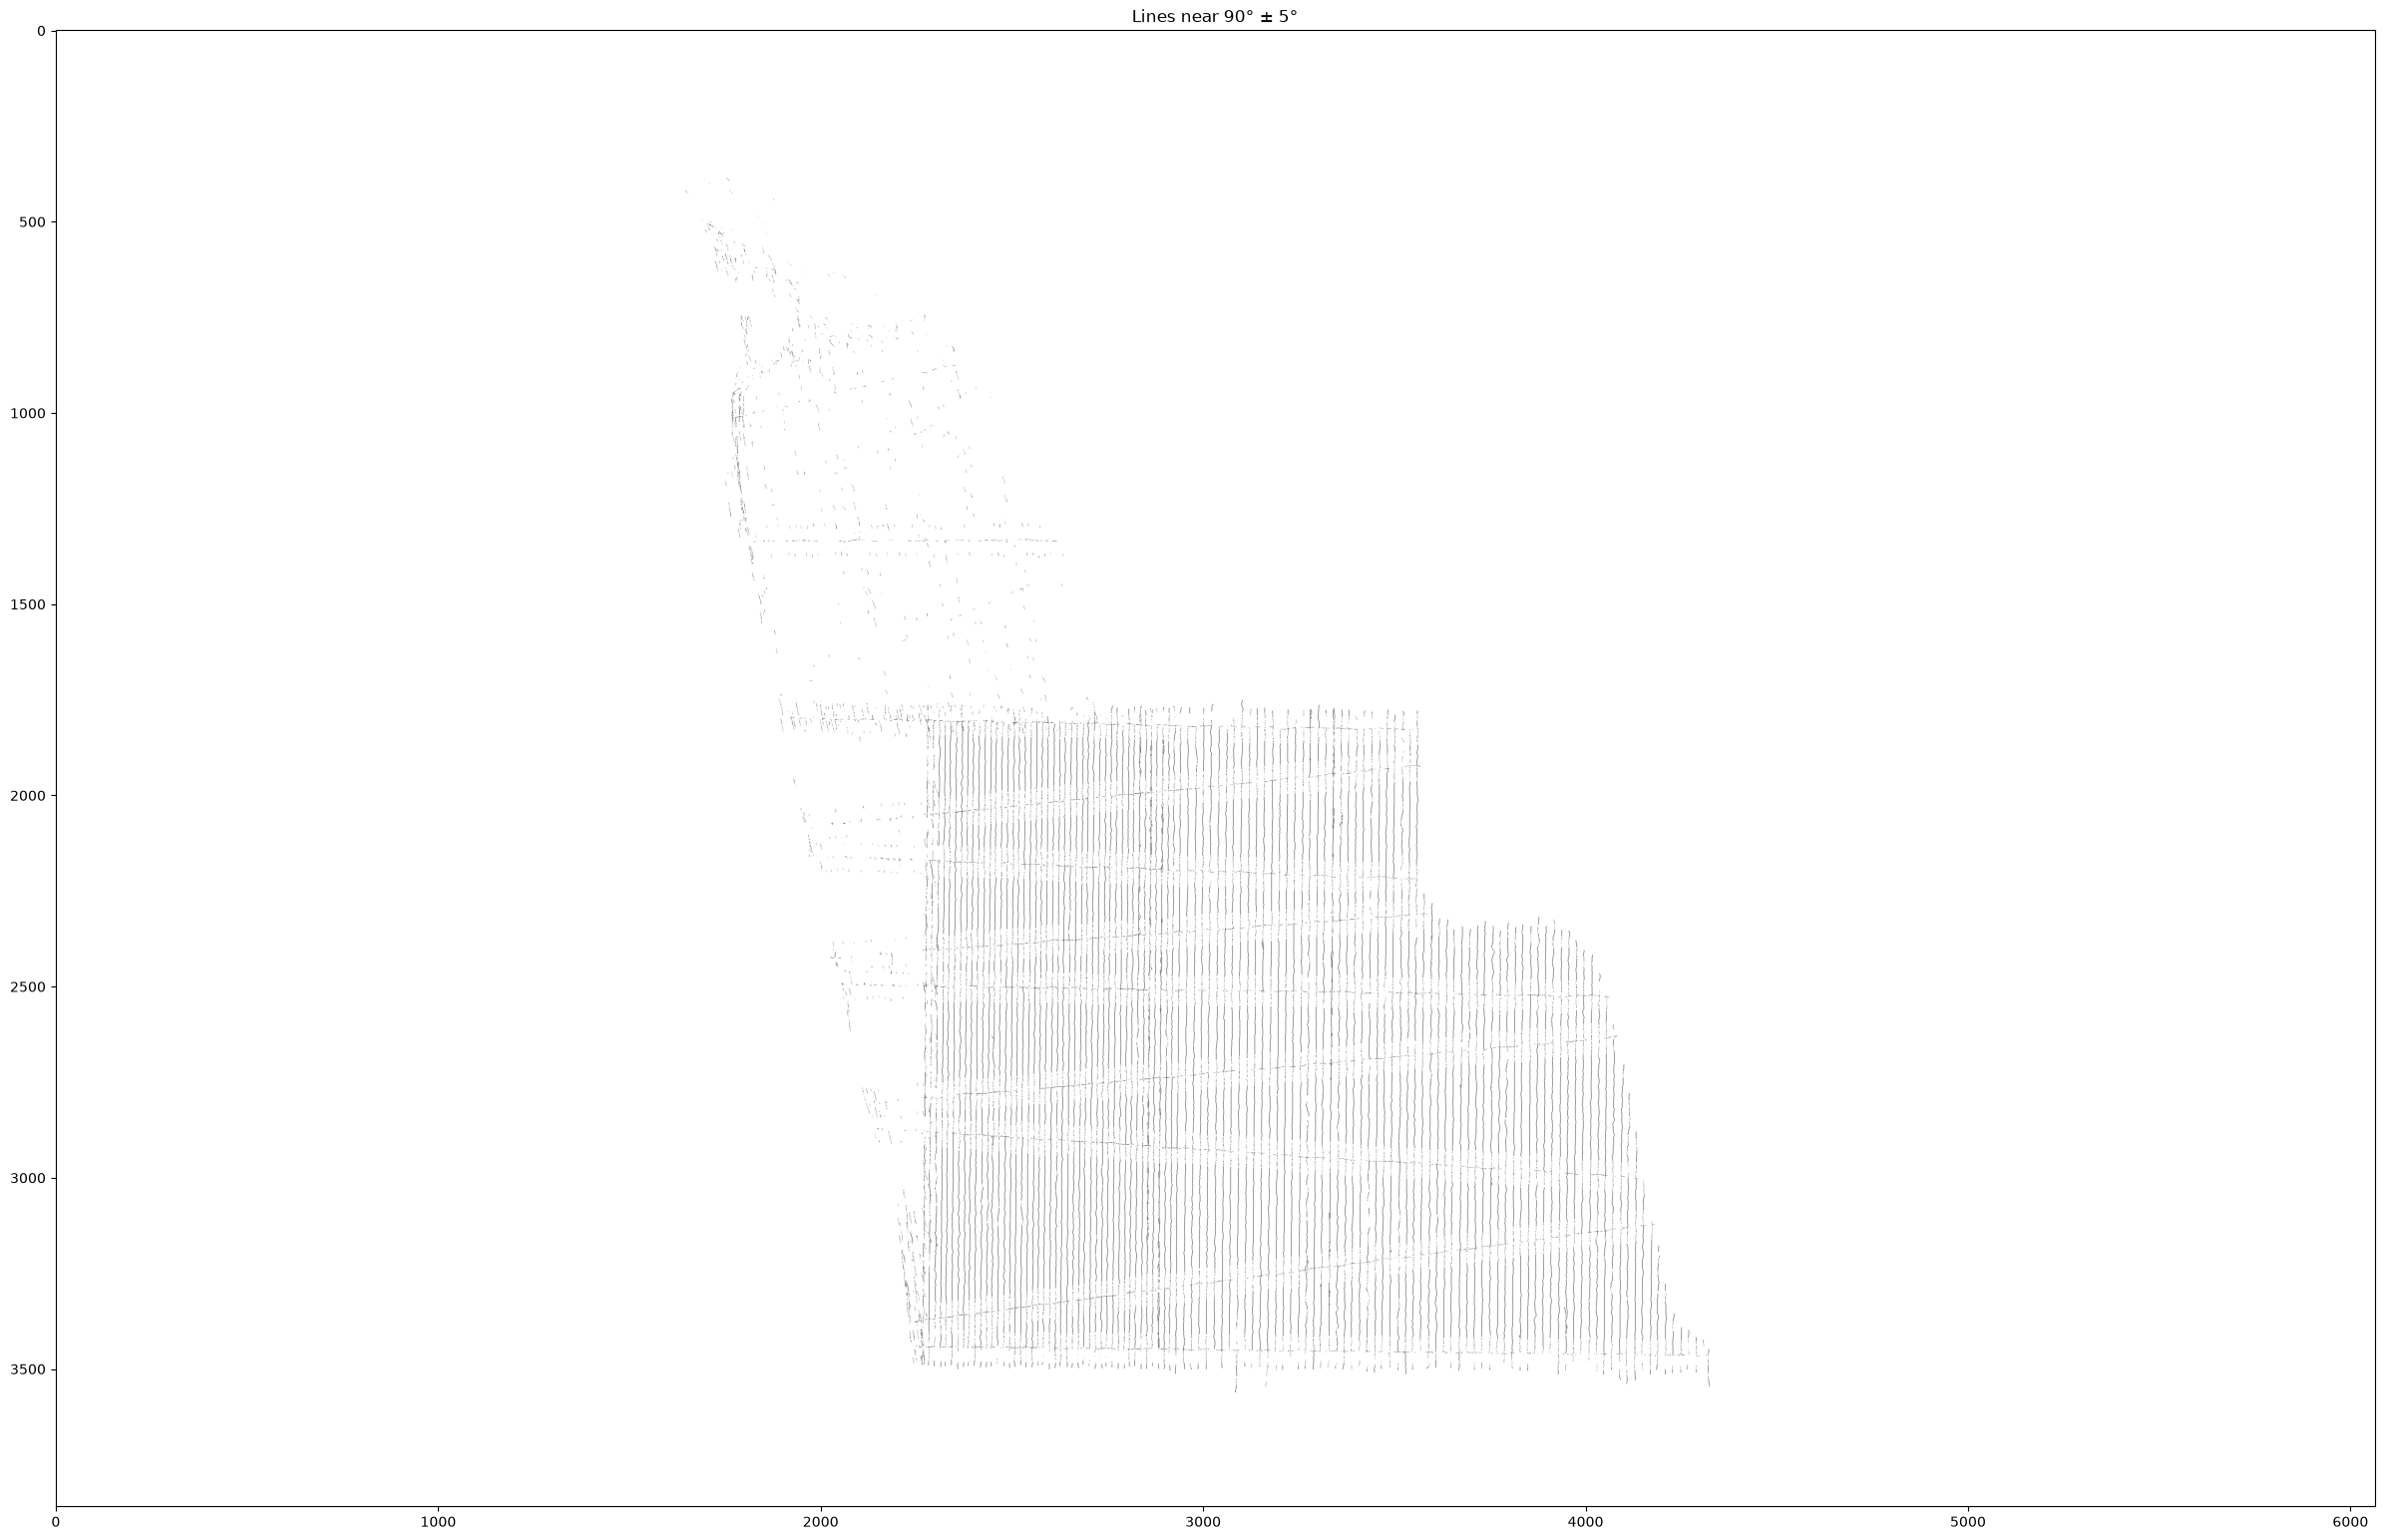

Extracting lines around 103° ± 5°
  Angle range: 98.0° to 108.0°


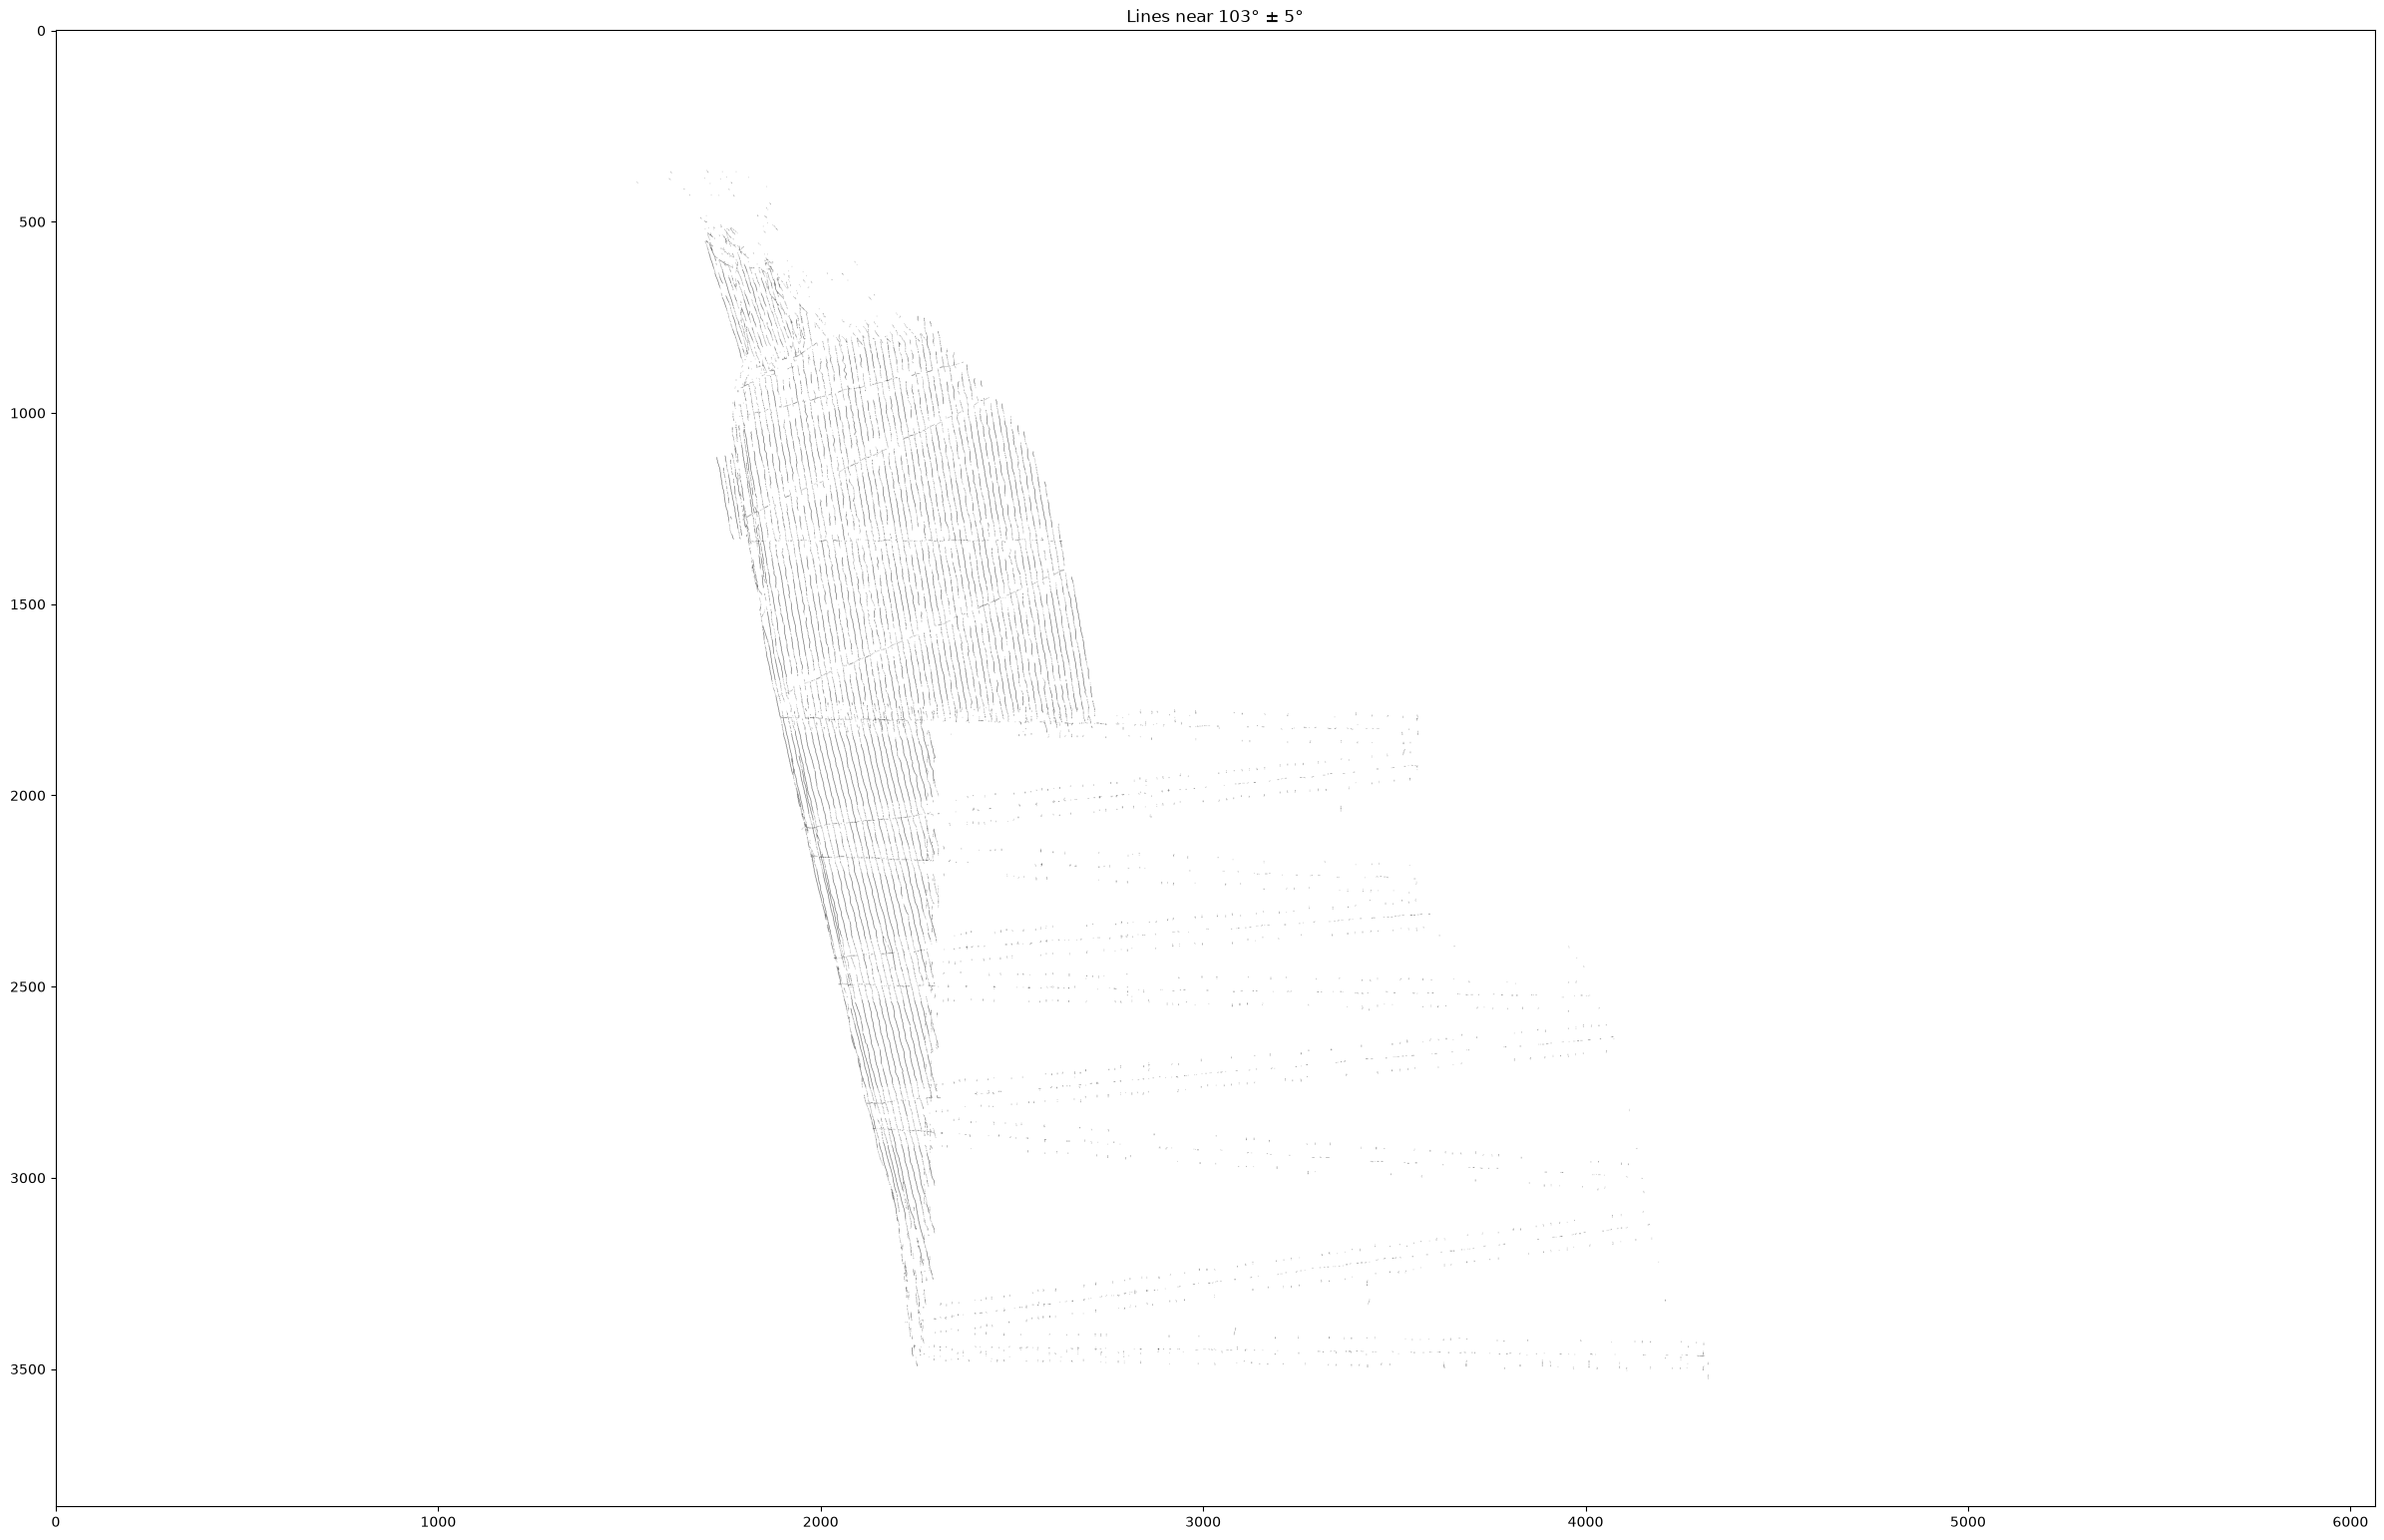

Extracting lines around 129° ± 5°
  Angle range: 124.0° to 134.0°


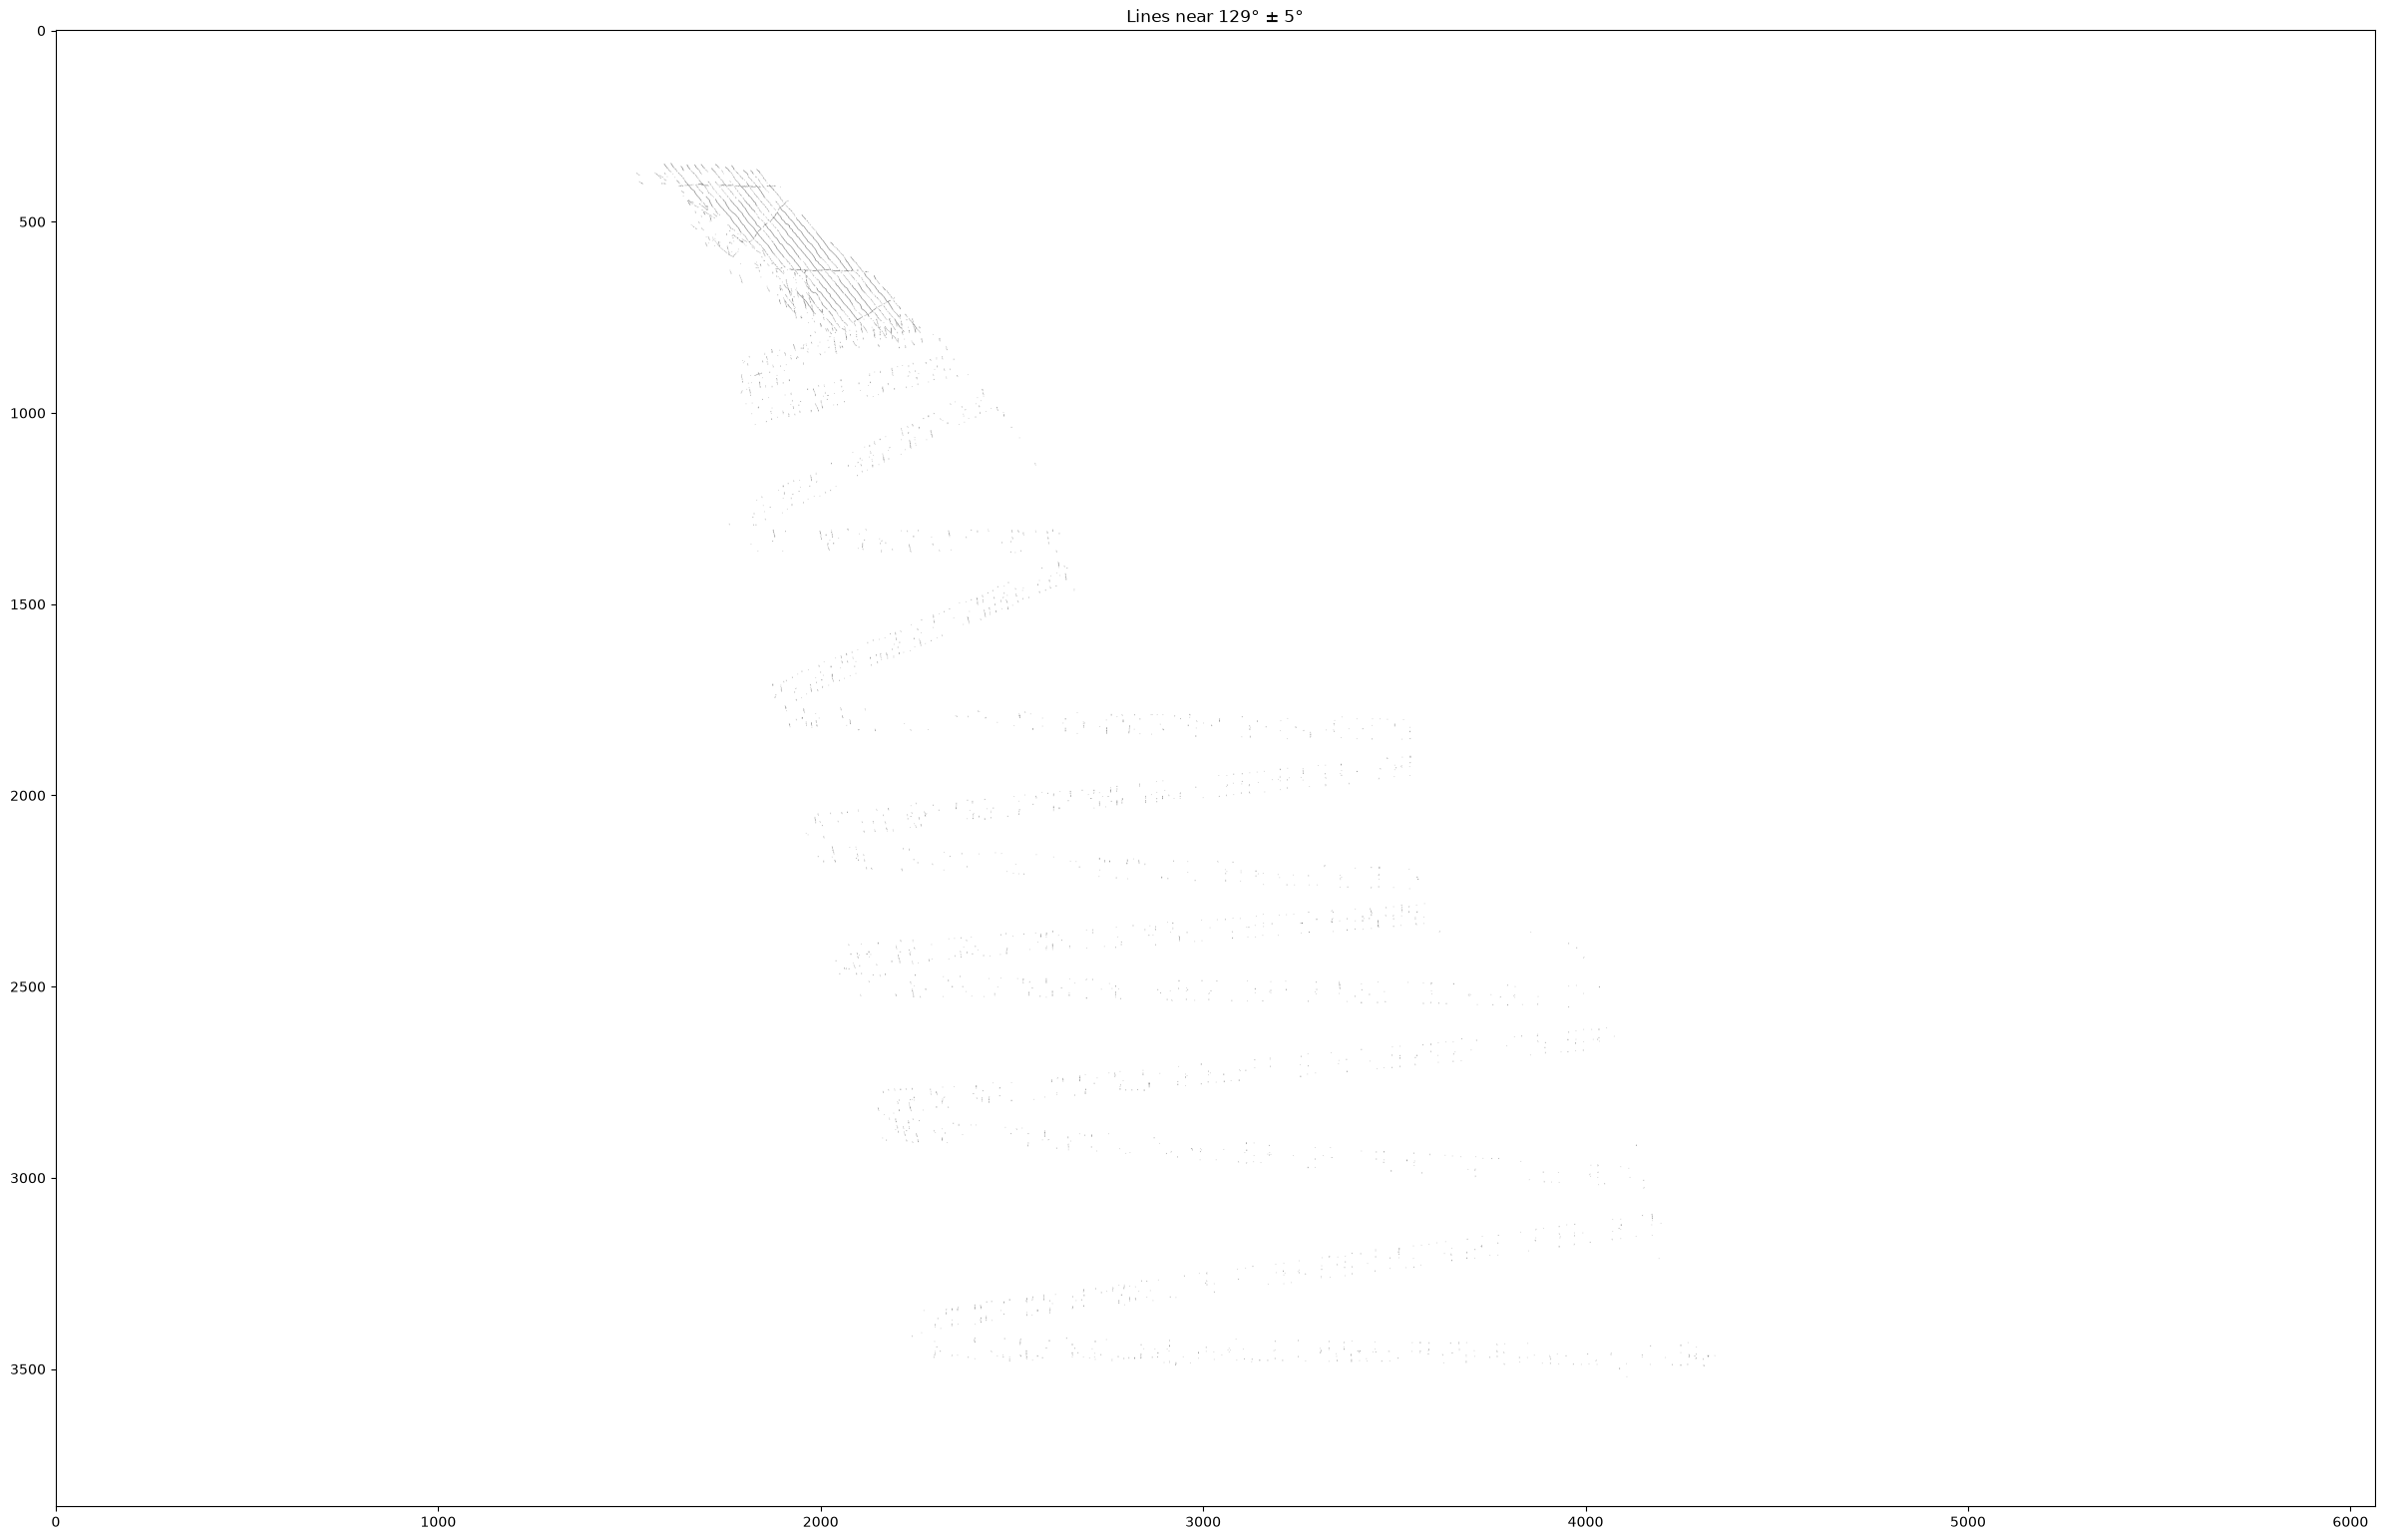

In [11]:
# Use 10% of longest dimension as the minimum line length
# this is a heuristic that captures the scale of features we expect to see
# Adjust as needed for different datasets.
min_line_pct = 0.02
min_line_length = int(min_line_pct * max(bathy_thin.shape))
print(f"Using min_line_length = {min_line_length} pixels "
      f"({min_line_pct*100:.1f}% of max dimension)")


if len(TARGET_ANGLES) > 1:
    angle_search_window = int(np.floor(np.min(np.diff(TARGET_ANGLES))) - 1) // 2
    TOLERANCE = angle_search_window # degrees of tolerance around each target angle
    TOLERANCE = min(TOLERANCE, 5)  # Ensure at least 5 degrees of tolerance
else:
    TOLERANCE = 5

angle_colors = plt.cm.viridis(np.linspace(0, 1, len(TARGET_ANGLES)))

angles_rasters = {}

for i, angle in enumerate(TARGET_ANGLES):
    print(f"Extracting lines around {angle}° ± {TOLERANCE}°")
    # Extract lines near this angle
    low_bound = (angle - TOLERANCE) % 180
    high_bound = (angle + TOLERANCE) % 180
    print(f"  Angle range: {low_bound:.1f}° to {high_bound:.1f}°")
    # Create a mask of pixels whose local orientation falls within this range
    if low_bound < high_bound:
        range_condition = np.logical_and(local_orientations >= low_bound, 
                                         local_orientations < high_bound,
                                         ~np.isnan(local_orientations))
    else:
        range_condition = np.logical_or(local_orientations >= low_bound, 
                                        local_orientations < high_bound,
                                        ~np.isnan(local_orientations))
        
    angles_rasters[angle] = range_condition
    
    plt.figure(figsize=(30, 30))
    plt.imshow(1 - range_condition.astype(bool), cmap='gray')
    plt.title(f"Lines near {angle}° ± {TOLERANCE}°")
    plt.show()

    

7. For each extracted family, assign real depth values based on original data
8. With each extracted family now consisting of parallel lines, we can process pairs of lines iteratively

For each pair of lines:

9. Interpolated bathymetry values of there are gaps within the lines
10. Compute the uncertainty for each line in the pair using the spectral energy using distance between the pair of lines as "linespacing"
11. Divide each line into subsegments with lengths equal to linespacing and apply spectral energy computation on each subsegment resulting to 2D array of spectral energies
12. Place the computed 2D arrays to the space between the line pairs

After processing all line pairs:

13. Rotate the resulting raster back to its original orientation (negative of dominant angle)
14. Plot the resulting raster

Angle 90°: detected 39 tracklines at columns [1788 2226 2303 2344 2404 2454 2496 2541 2586 2630 2707 2751 2796 2856
 2918 2960 3012 3076 3156 3212 3280 3332 3375 3434 3478 3540 3615 3674
 3732 3790 3832 3873 3934 4011 4054 4130 4172 4228 4321]


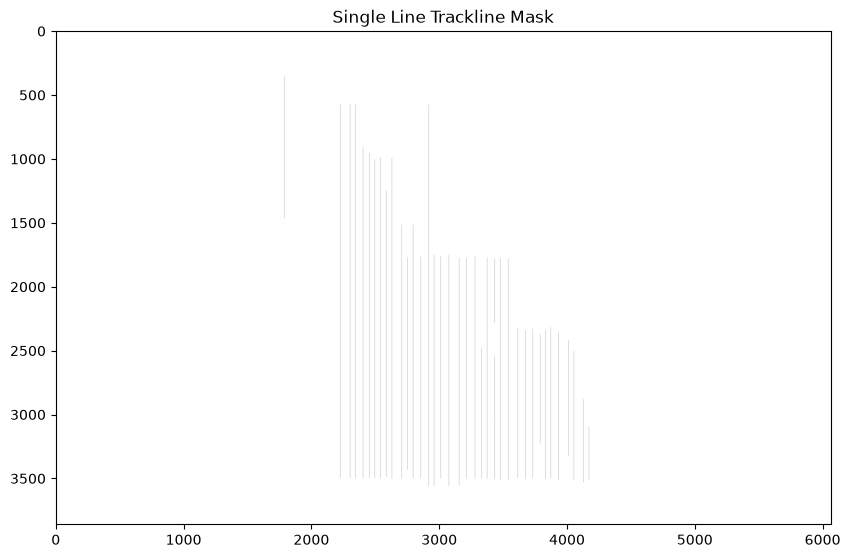

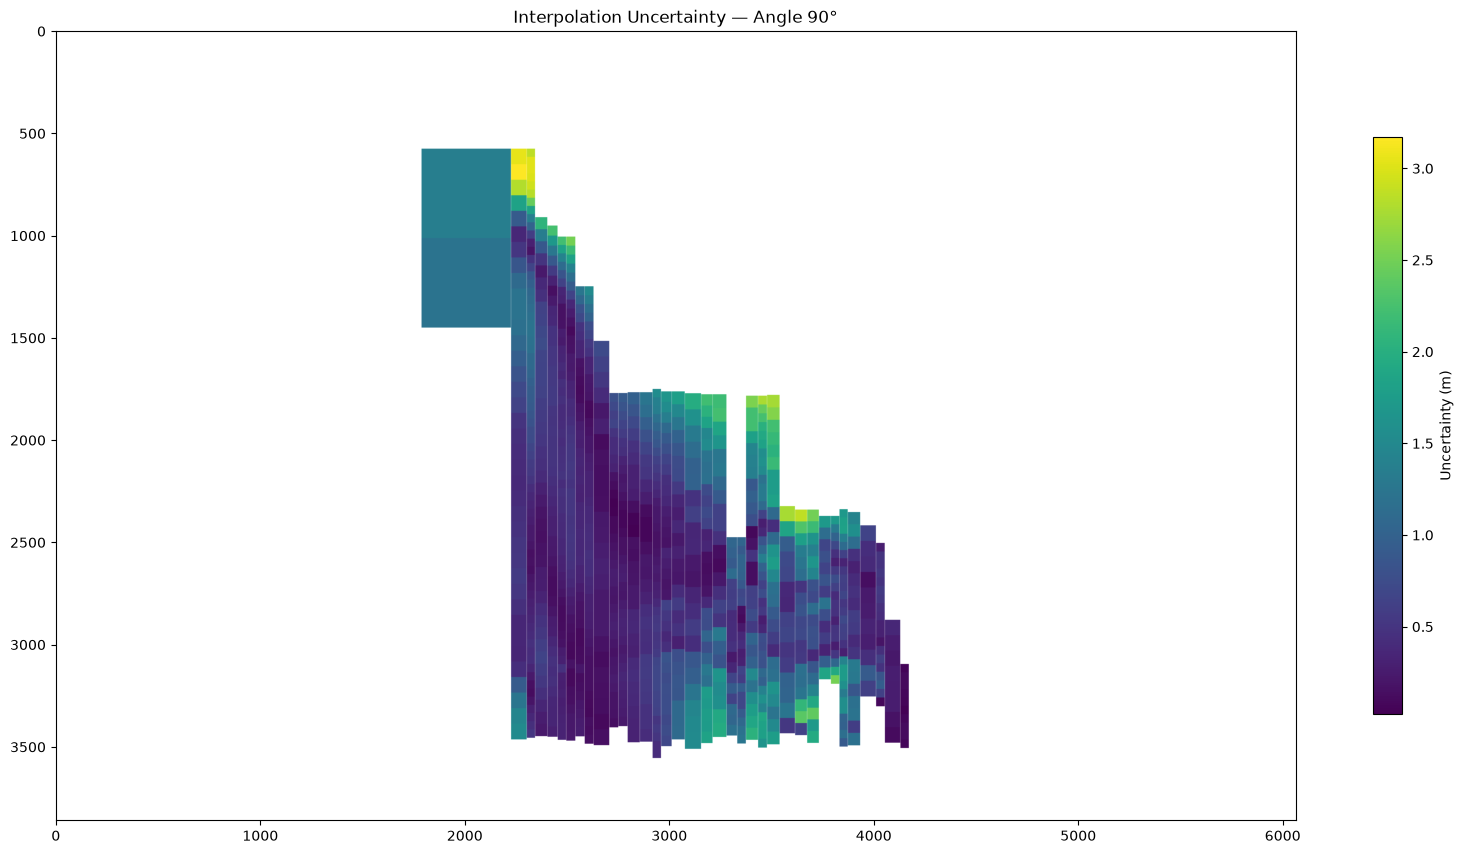

Angle 103°: detected 14 tracklines at columns [2327 2382 2426 2486 2531 2575 2635 2760 2807 2858 2922 3010 3070 3116]


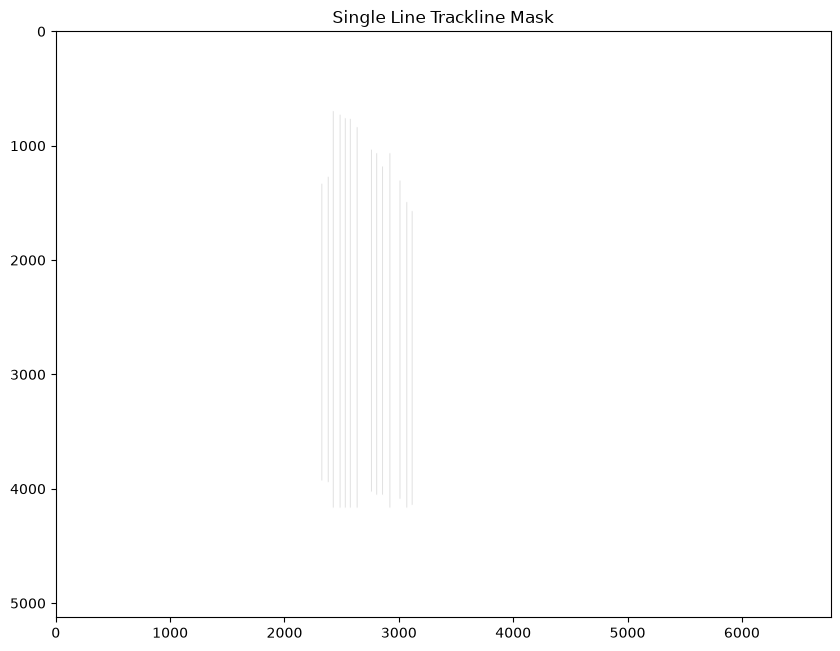

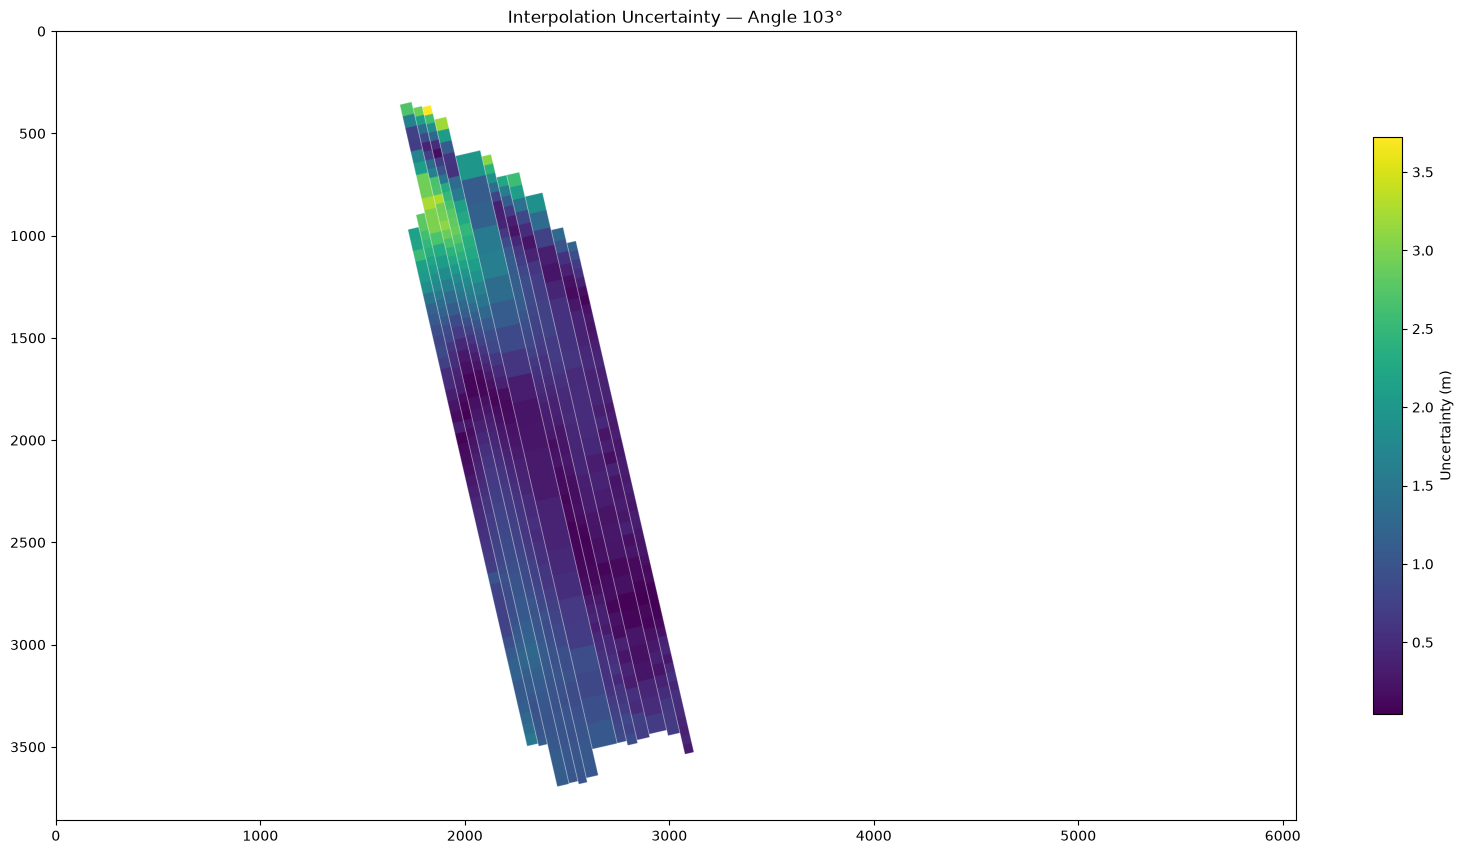

Angle 129°: detected 6 tracklines at columns [3415 3460 3521 3582 3626 3672]


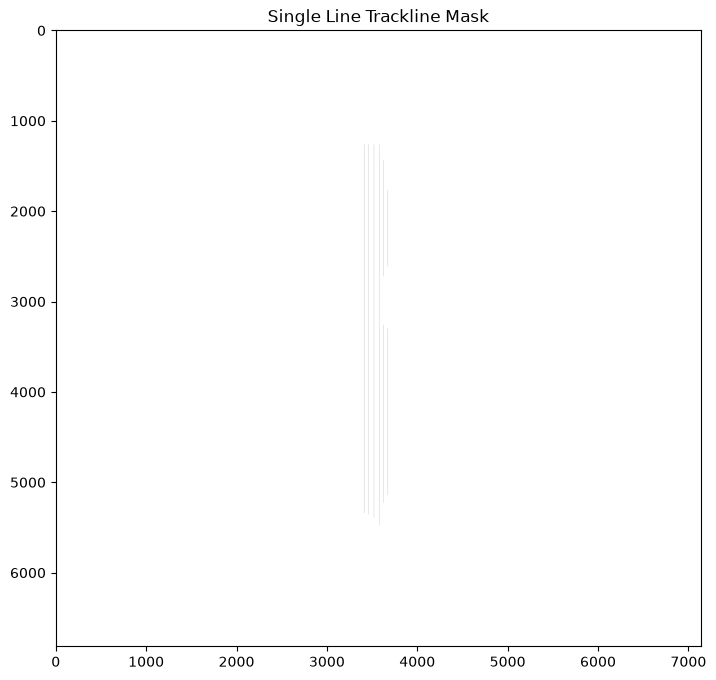

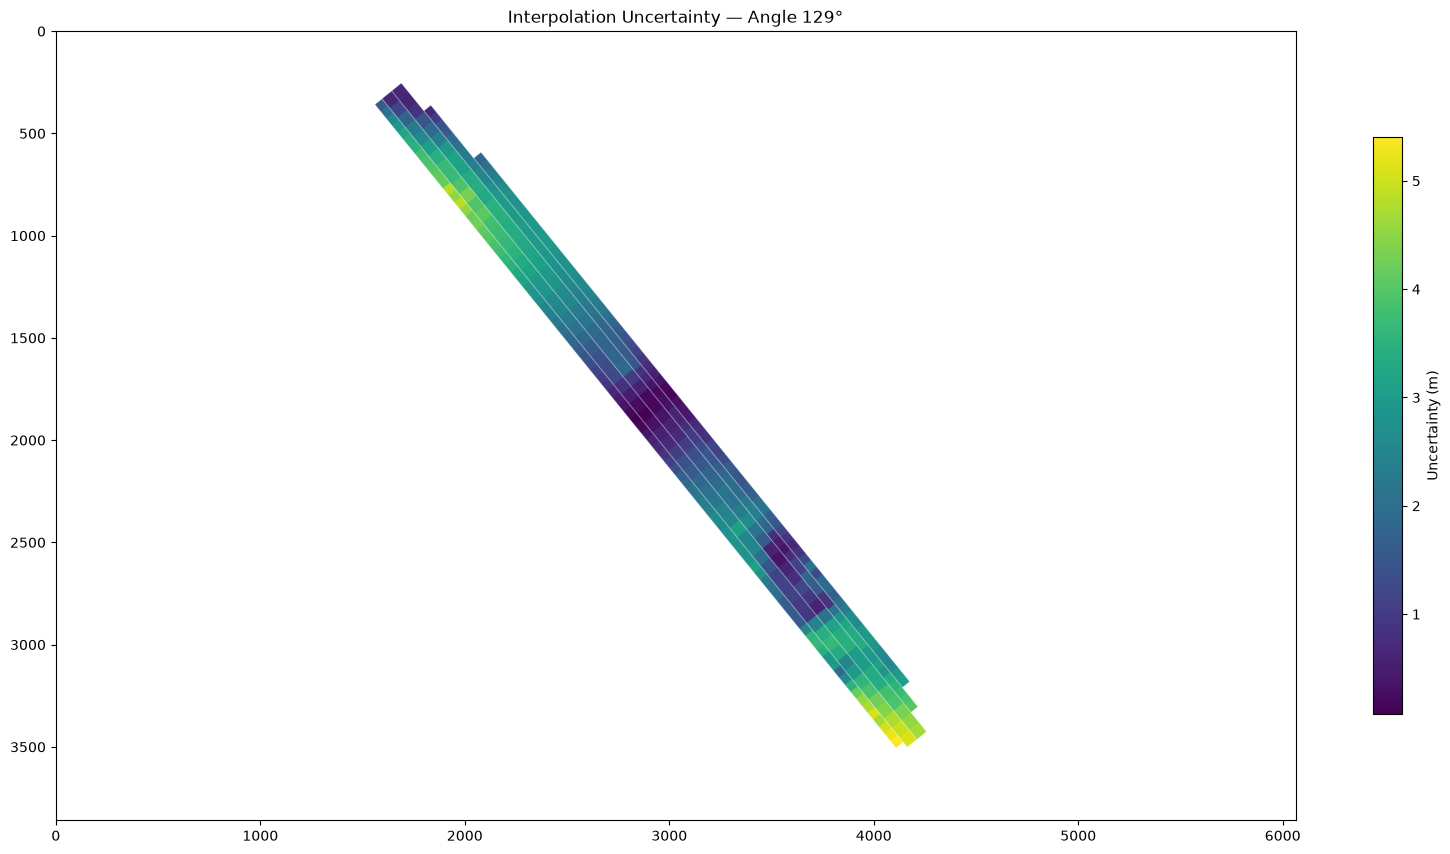

In [15]:
min_line_factor = 0.1  # fraction of max projection height used as the peak threshold
band_width      = 40   # minimum column separation between adjacent detected peaks (pixels)

uncertainty_results = {}  # keyed by angle — stores the final uncertainty raster per family

for angle in TARGET_ANGLES:
    current_mask = angles_rasters[angle]

    # --- Steps 7–8: Detect trackline positions and build the clean line mask ---
    peaks, restored_mask, angle_to_rotate = detect_trackline_positions(
        angle_mask=current_mask,
        bathy_binary=bathy_binary,
        angle=angle,
        min_line_factor=min_line_factor,
        band_width=band_width,
    )
    print(f"Angle {angle}°: detected {len(peaks)} tracklines at columns {peaks}")

    # Plot restored mask
    plt.figure(figsize=(10, 8))
    plt.imshow(1 - restored_mask, cmap='gray')
    plt.title("Single Line Trackline Mask")

    # Assign real depth values from bathy_data to each detected line pixel
    current_depth_raster = assign_depths_to_lines(
        restored_mask=restored_mask,
        bathy_binary=bathy_binary,
        bathy_data=bathy_data,
        angle_to_rotate=angle_to_rotate,
    )

    # --- Steps 9–12: Process all adjacent line pairs → uncertainty raster ---
    uncertainty_raster = build_uncertainty_raster(
        peaks=peaks,
        restored_mask=restored_mask,
        current_depth_raster=current_depth_raster,
        resolution=bathy_data['metadata']['resolution'],
    )

    # --- Step 13: Rotate uncertainty raster back to original orientation ---
    uncertainty_original = undo_rotation(
        raster=uncertainty_raster,
        angle_to_rotate=angle_to_rotate,
        original_shape=current_mask.shape,
    )

    uncertainty_results[angle] = uncertainty_original

    # --- Step 14: Plot ---
    plt.figure(figsize=(20, 15))
    plt.imshow(uncertainty_original, cmap='viridis')
    plt.colorbar(label='Uncertainty (m)', shrink=0.5)
    plt.title(f'Interpolation Uncertainty — Angle {angle}°')
    plt.show()


In [13]:
## ── Method comparison ────────────────────────────────────────────────────────
# Run the pipeline for every spectral method in compute_uncertainty and display
# the resulting uncertainty rasters side-by-side so the effect of each method
# on the uncertainty estimate can be assessed visually.
#
# Strategy:
#   - detect_trackline_positions + assign_depths_to_lines are method-independent
#     (pure geometry + depth lookup), so we compute them ONCE per angle and cache.
#   - build_uncertainty_raster is then run for each method — fast because it
#     only redoes the FFT step.

METHODS = ['amplitude', 'psd', 'psd_n', 'psd_df']

# --- Step A: Cache geometry + depth for each angle (run once) ---
angle_cache = {}
for angle in TARGET_ANGLES:
    current_mask = angles_rasters[angle]
    peaks, restored_mask, angle_to_rotate = detect_trackline_positions(
        angle_mask=current_mask,
        bathy_binary=bathy_binary,
        angle=angle,
        min_line_factor=min_line_factor,
        band_width=band_width,
    )
    current_depth_raster = assign_depths_to_lines(
        restored_mask=restored_mask,
        bathy_binary=bathy_binary,
        bathy_data=bathy_data,
        angle_to_rotate=angle_to_rotate,
    )
    angle_cache[angle] = dict(
        current_mask=current_mask,
        peaks=peaks,
        restored_mask=restored_mask,
        angle_to_rotate=angle_to_rotate,
        current_depth_raster=current_depth_raster,
    )



Processing angle 90° with method 'amplitude' with ax Axes(0.125,0.712609;0.775x0.167391)...
Processing angle 90° with method 'psd' with ax Axes(0.125,0.511739;0.775x0.167391)...
Processing angle 90° with method 'psd_n' with ax Axes(0.125,0.31087;0.775x0.167391)...
Processing angle 90° with method 'psd_df' with ax Axes(0.125,0.11;0.775x0.167391)...
Processing angle 103° with method 'amplitude' with ax Axes(0.125,0.712609;0.775x0.167391)...
Processing angle 103° with method 'psd' with ax Axes(0.125,0.511739;0.775x0.167391)...
Processing angle 103° with method 'psd_n' with ax Axes(0.125,0.31087;0.775x0.167391)...
Processing angle 103° with method 'psd_df' with ax Axes(0.125,0.11;0.775x0.167391)...
Processing angle 129° with method 'amplitude' with ax Axes(0.125,0.712609;0.775x0.167391)...
Processing angle 129° with method 'psd' with ax Axes(0.125,0.511739;0.775x0.167391)...
Processing angle 129° with method 'psd_n' with ax Axes(0.125,0.31087;0.775x0.167391)...
Processing angle 129° with m

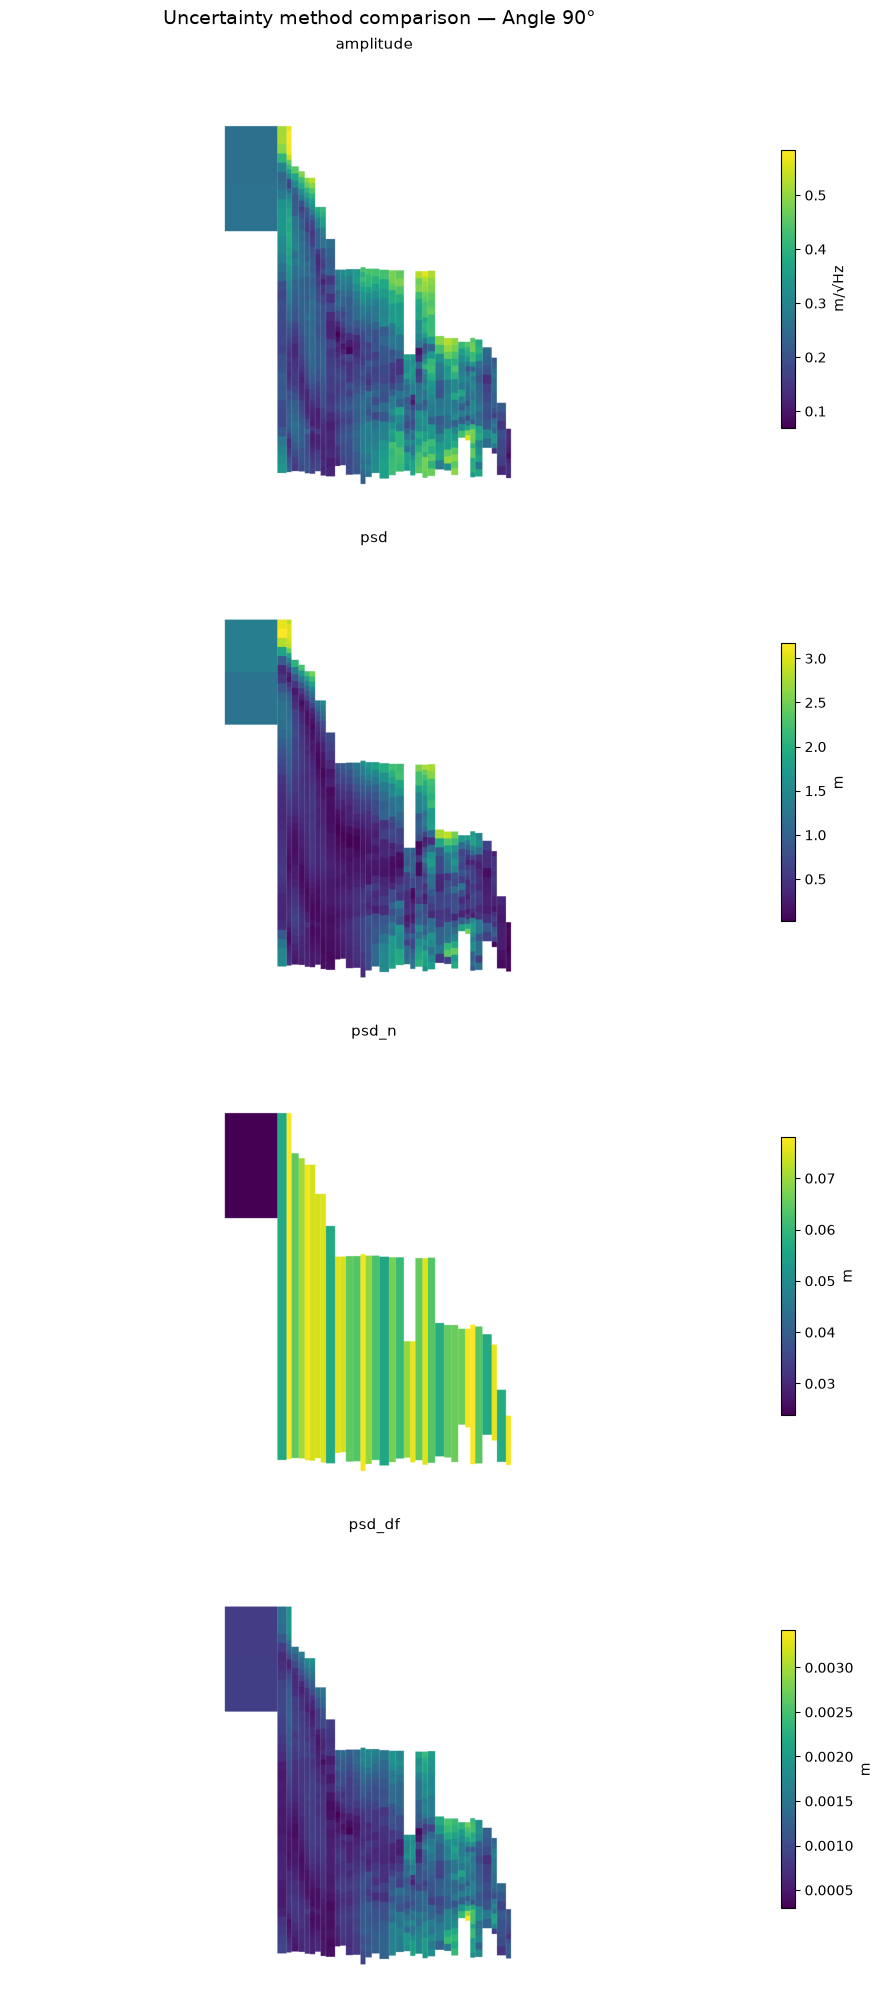

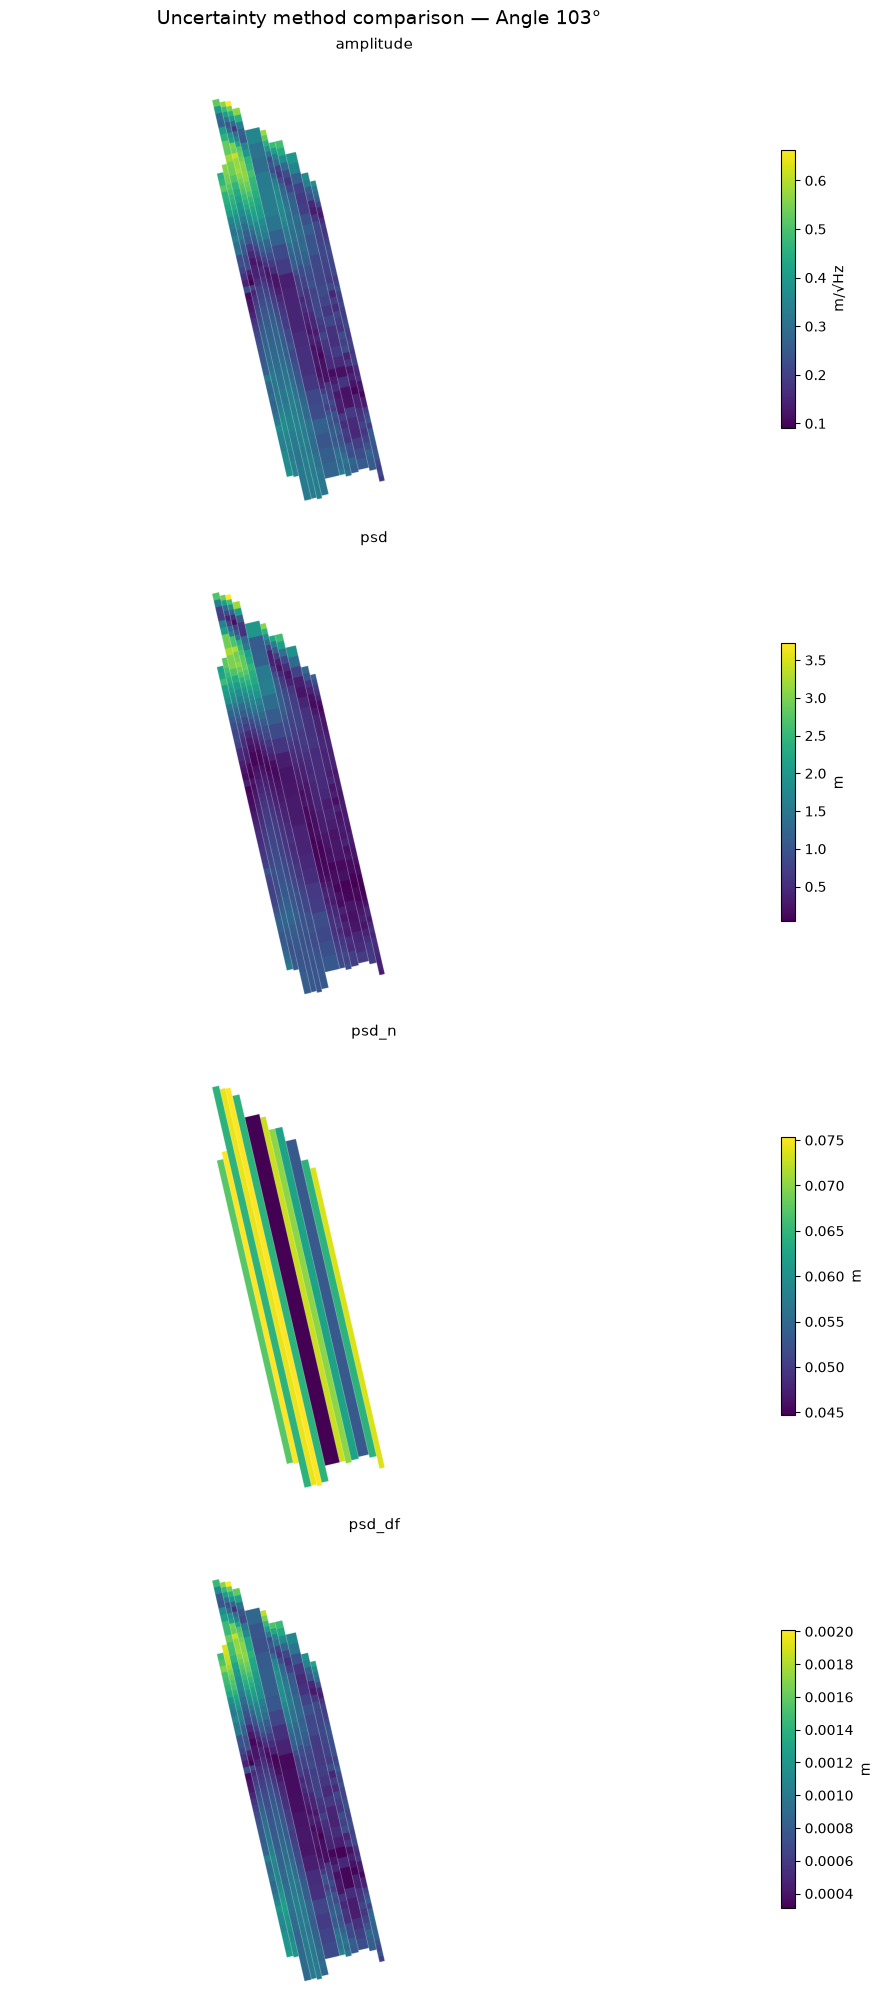

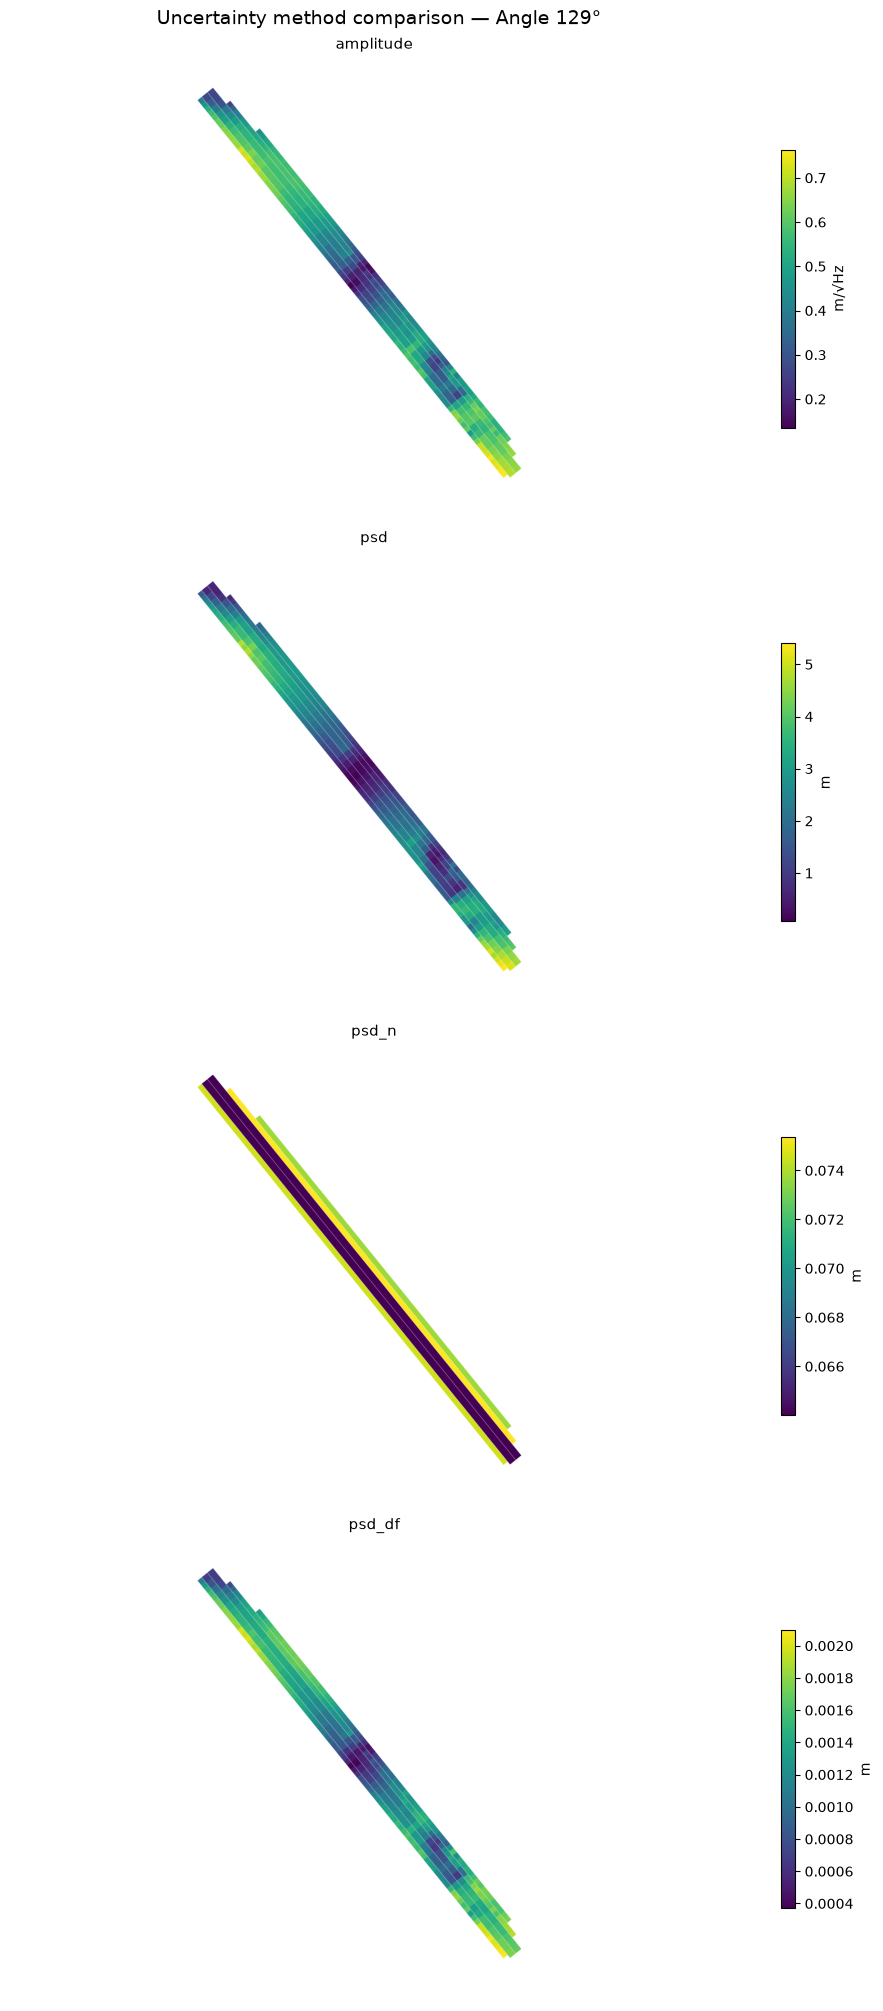

In [14]:
# --- Step B: Loop over methods and plot a row of subplots per angle ---
resolution = bathy_data['metadata']['resolution']

for angle, cache in angle_cache.items():
    n_methods = len(METHODS)
    fig, axes = plt.subplots(n_methods, 1, figsize=(10, 5 * n_methods),
                             constrained_layout=True)
    fig.suptitle(f'Uncertainty method comparison — Angle {angle}°', fontsize=14)
    for ax, method in zip(axes.flatten(), METHODS):
        print(f"Processing angle {angle}° with method '{method}' with ax {ax}...")
        uncertainty_raster = build_uncertainty_raster(
            peaks=cache['peaks'],
            restored_mask=cache['restored_mask'],
            current_depth_raster=cache['current_depth_raster'],
            resolution=resolution,
            method=method,
        )
        uncertainty_original = undo_rotation(
            raster=uncertainty_raster,
            angle_to_rotate=cache['angle_to_rotate'],
            original_shape=cache['current_mask'].shape,
        )
        im = ax.imshow(uncertainty_original, cmap='viridis')
        ax.set_title(method, fontsize=11)
        ax.axis('off')
        plt.colorbar(im, ax=ax, shrink=0.6,
                     label='m' if method != 'amplitude' else 'm/√Hz')

plt.show()